# 🏭 Pakistan Sugar Mills: Big Data Analytics, Data Warehousing & Data Mining

**Courses:** Big Data Analytics · Data Warehouse and Data Mining
**Tools:** PySpark (Spark SQL, Spark MLlib), pandas, matplotlib, seaborn, scikit-learn (metrics only)

<a href="https://colab.research.google.com/github/GITHUB_USERNAME/pakistan-sugar-mills-analytics/blob/main/notebooks/Pakistan_Sugar_Mills_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Problem statement
Pakistan is one of the world's larger sugar producers, with roughly 80+ mills in Punjab, Sindh and Khyber Pakhtunkhwa (KPK).
Every crushing season (November to April) mills buy millions of tonnes of sugarcane from growers, crush it and turn about 9 to 10% of it into sugar
(the **recovery rate**). Three recurring problems in the industry are:
1. **Low and variable sugar recovery**, which wastes cane and raises cost per kg of sugar.
2. **Late payments to cane growers**, a long-standing complaint in Punjab and Sindh.
3. **Unequal mill performance** (old vs modern mills, cogeneration, breakdowns).

## Objectives
| # | Objective | Course topic |
|---|---|---|
| 1 | Ingest and clean ~1 million procurement records + ~86k mill-day records with PySpark | Big Data |
| 2 | Design and build a **galaxy (fact constellation) schema** data warehouse, stored as partitioned Parquet | Data Warehouse |
| 3 | Run **OLAP operations** (roll-up, drill-down, slice, dice, pivot, cube) with Spark SQL | Data Warehouse |
| 4 | Predict **daily sugar recovery %** (regression: Linear, Random Forest, GBT) | Machine Learning |
| 5 | Predict **late grower payments** (classification: Logistic Regression, Random Forest, GBT) | Machine Learning |
| 6 | **K-Means clustering** of mills into performance segments | Data Mining |
| 7 | **FP-Growth association rules** on cane receipts | Data Mining |

## Dataset (hybrid: real + simulated)
* **Real data (`data/real/`)**: published PBS, PSMA, Crop Reporting Service Punjab, Economic Survey and USDA GAIN figures:
  province-wise cane area/production 2000-2023, mill crushing and recovery 1997-2011, national crushing 2015-2020 and minimum support prices.
* **Simulated big data (`data/synthetic/`)**: mill-level and receipt-level data is not published in Pakistan, so it was generated by
  `src/generate_data.py` and **calibrated to the real figures** (national cane crushed and sugar produced per season, province shares,
  recovery levels, support prices, crushing calendar). Mill names are anonymised codes; district names and cane variety codes are real.
  All mill, grower and receipt values are simulated and must not be read as facts about any real mill.

| Table | Rows | Grain |
|---|---|---|
| `cane_procurement/*.csv.gz` | ~980,000 | one weighbridge receipt (cane delivery) |
| `daily_crushing.csv.gz` | ~85,000 | one mill on one crushing day |
| `mills.csv` | 85 | mill |
| `growers.csv.gz` | ~86,000 | cane grower |
| `varieties.csv`, `districts.csv` | small | lookup |

## 0. Setup
In **Google Colab**: set `GITHUB_USERNAME` below to your GitHub username, then run all cells (Runtime → Run all).
The cell installs PySpark, clones the repository and (if needed) regenerates the dataset. Running locally needs Python 3.9+, Java 11/17 and `pip install -r requirements.txt`.

In [1]:
# ============================================================
# SETUP CELL: prepares the environment (Colab or your own PC)
# ============================================================
import os, sys, subprocess, shutil, time, warnings   # standard Python helpers (files, shell commands, timing)
warnings.filterwarnings("ignore")                      # hide noisy library warnings so outputs stay clean

GITHUB_USERNAME = "your-github-username"          # <-- change this to your GitHub username
REPO_NAME = "pakistan-sugar-mills-analytics"      # name of the GitHub repository (do not change)
IN_COLAB = "google.colab" in sys.modules          # True when this notebook is running inside Google Colab

if IN_COLAB:
    # Spark is written in Java/Scala, so it needs Java. Install it only if it is missing.
    if shutil.which("java") is None:                 # Spark needs Java
        subprocess.run("apt-get -qq install -y openjdk-17-jre-headless > /dev/null", shell=True)
    # Install PySpark (the Python interface to Apache Spark). Version is fixed so results are reproducible.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark==3.5.3"])
    # Download (clone) the project from GitHub into Colab, unless it is already there.
    PROJECT_DIR = f"/content/{REPO_NAME}"
    if not os.path.exists(PROJECT_DIR):
        subprocess.run(["git", "clone", "--depth", "1",
                        f"https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git", PROJECT_DIR])
else:
    # Running on your own computer: the project folder is the parent of the "notebooks" folder.
    PROJECT_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()

# If the dataset files are missing for any reason, rebuild them with the generator script.
DATA = os.path.join(PROJECT_DIR, "data")
if not os.path.exists(os.path.join(DATA, "synthetic", "daily_crushing.csv.gz")):
    print("Dataset not found, generating it (about 1 minute)...")
    subprocess.run([sys.executable, os.path.join(PROJECT_DIR, "src", "generate_data.py")], check=True)

# Folders used later in the notebook
WAREHOUSE = os.path.join(PROJECT_DIR, "warehouse")         # where the Parquet data warehouse will be saved
FIG_DIR = os.path.join(PROJECT_DIR, "outputs", "figures")  # where charts are saved as PNG files
OUT_DIR = os.path.join(PROJECT_DIR, "outputs")             # where result tables (CSV) are saved
os.makedirs(FIG_DIR, exist_ok=True)                        # create the folders if they do not exist
print("Project folder:", PROJECT_DIR)
print("Running in Colab:", IN_COLAB)

Project folder: /home/claude/pakistan-sugar-mills-analytics
Running in Colab: False


In [2]:
# ============================================================
# LIBRARIES + START THE SPARK SESSION
# ============================================================
import numpy as np                 # numerical computing (arrays, maths)
import pandas as pd                # small tables in memory (used for results and plotting)
import matplotlib.pyplot as plt    # charts
import seaborn as sns              # nicer statistical charts on top of matplotlib
from pyspark.sql import SparkSession, functions as F, Window   # Spark entry point, column functions, window functions
from pyspark.sql.types import (StructType, StructField, StringType, IntegerType, DoubleType, DateType)  # data types for schemas

# SparkSession = the "engine" that runs all big data operations.
spark = (SparkSession.builder
         .appName("PakistanSugarMills")                               # name shown in the Spark UI
         .master("local[*]")                                          # run locally using ALL CPU cores of this machine
         .config("spark.driver.memory", "6g" if IN_COLAB else "4g")   # RAM Spark may use
         .config("spark.sql.shuffle.partitions", "16")                # number of chunks after groupBy/join (default 200 is too many for a small machine)
         .config("spark.sql.adaptive.enabled", "true")                # Adaptive Query Execution: Spark re-optimises queries while running
         .config("spark.ui.showConsoleProgress", "false")             # hide the progress bars in the output
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")                               # only print real errors, not info/warnings

sns.set_theme(style="whitegrid", palette="deep")                      # chart style for the whole notebook
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)   # show wide tables fully

# Small helper: tidy the layout, save the current chart to outputs/figures/, then display it.
def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=110, bbox_inches="tight")
    plt.show()

print("Spark version:", spark.version, "| cores:", spark.sparkContext.defaultParallelism)

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=41155 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up _JAVA_OPTIONS: -XX:+UnlockDiagnosticVMOptions -XX:DisableIntrinsic=_base64_encodeBlock,_base64_decodeBlock


Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=41155 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up _JAVA_OPTIONS: -XX:+UnlockDiagnosticVMOptions -XX:DisableIntrinsic=_base64_encodeBlock,_base64_decodeBlock


26/11/25 15:51:07 WARN Utils: Your hostname, vm resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/25 15:51:07 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/25 15:51:09 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 3.5.3 | cores: 2


## 1. Real data: the industry at a glance
Small official tables, so pandas is enough here. They give context and the calibration targets for the simulated data.

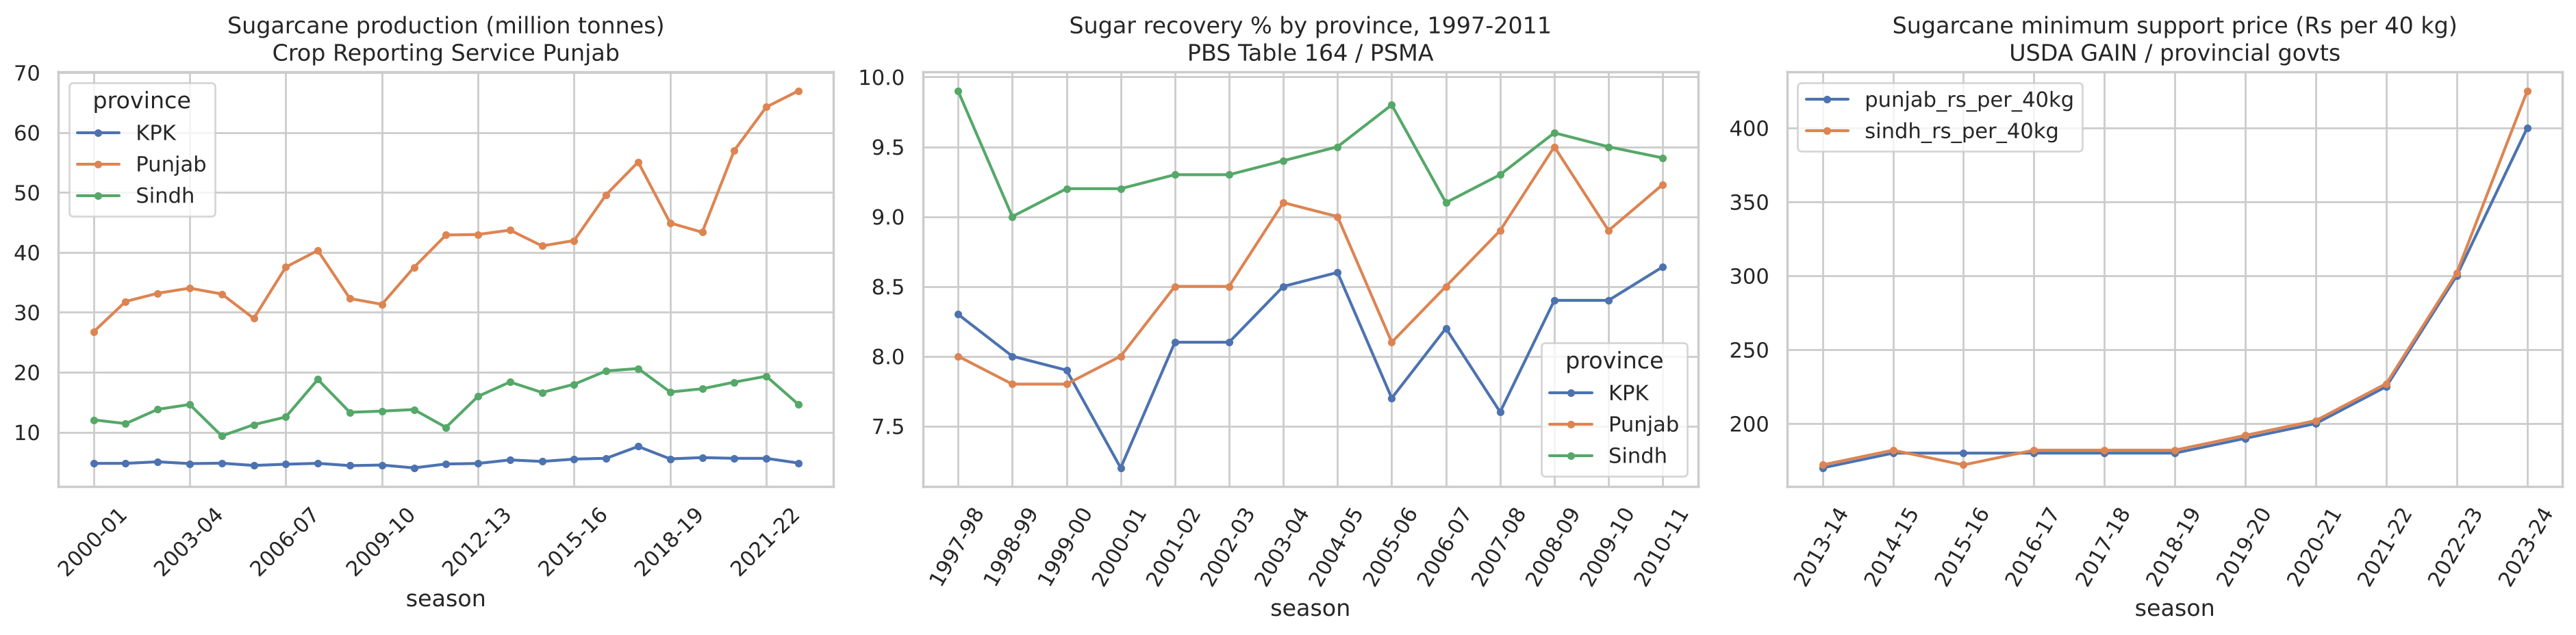

,avg_recovery,avg_mills,avg_crushed_mt
province,,,
KPK,8.12,5.79,1.87
Punjab,8.56,40.07,24.25
Sindh,9.39,28.36,11.90


In [3]:
# ============================================================
# REAL DATA: read the small official tables with pandas and plot them
# ============================================================
real_area = pd.read_csv(f"{DATA}/real/sugarcane_area_production_province_2000_2023.csv")   # cane area & production by province
real_mills = pd.read_csv(f"{DATA}/real/sugar_industry_province_1997_2011.csv")             # mills, crushing, recovery by province
real_nat = pd.read_csv(f"{DATA}/real/sugar_national_crushing_2015_2020.csv")               # national crushing & sugar output
msp = pd.read_csv(f"{DATA}/real/sugarcane_min_support_price_2013_2024.csv")                # government support price of cane

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))       # one figure with 3 charts side by side

# Chart 1: pivot turns the long table into one column per province, then we plot a line per province.
pv = (real_area[real_area.province != "Balochistan"]   # Balochistan grows almost no cane, so leave it out
      .pivot(index="season", columns="province", values="production_000_tonnes") / 1000)   # '000 t -> million t
pv.plot(ax=ax[0], marker="o", ms=3)
ax[0].set_title("Sugarcane production (million tonnes)\nCrop Reporting Service Punjab")
ax[0].set_xticks(range(0, len(pv), 3)); ax[0].set_xticklabels(pv.index[::3], rotation=45)   # show every 3rd season label

# Chart 2: sugar recovery % (sugar made per 100 kg of cane) by province
rv = real_mills.pivot(index="season", columns="province", values="recovery_pct")
rv.plot(ax=ax[1], marker="o", ms=3)
ax[1].set_title("Sugar recovery % by province, 1997-2011\nPBS Table 164 / PSMA")
ax[1].set_xticks(range(len(rv))); ax[1].set_xticklabels(rv.index, rotation=60)

# Chart 3: minimum support price that mills must pay growers
msp.set_index("season")[["punjab_rs_per_40kg", "sindh_rs_per_40kg"]].plot(ax=ax[2], marker="o", ms=3)
ax[2].set_title("Sugarcane minimum support price (Rs per 40 kg)\nUSDA GAIN / provincial govts")
ax[2].set_xticks(range(len(msp))); ax[2].set_xticklabels(msp.season, rotation=60)
savefig("01_real_data_overview.png")

# Summary table: average recovery, number of mills and cane crushed per province
summary = real_mills.groupby("province").agg(avg_recovery=("recovery_pct", "mean"),
                                             avg_mills=("no_of_mills", "mean"),
                                             avg_crushed_mt=("cane_crushed_mt", "mean")).round(2)
summary

**Observations (real data):** Punjab grows roughly two-thirds of Pakistan's cane, but Sindh mills consistently report a higher recovery rate
(warmer winters, longer-matured cane). Support prices were flat for years and then more than doubled between 2020-21 and 2023-24,
which raises the cost of every tonne of cane crushed.

## 2. Big data ingestion with PySpark
We read all 10 seasonal procurement files at once using a wildcard path and an **explicit schema**
(faster and safer than `inferSchema` on millions of rows).

In [4]:
# ============================================================
# INGESTION: load the big CSV files into Spark DataFrames
# ============================================================
# An explicit schema tells Spark the type of every column up front.
# This is faster than inferSchema (which would scan all ~1 million rows first) and prevents wrong type guesses.
procurement_schema = StructType([
    StructField("receipt_id", StringType()),      StructField("season", StringType()),
    StructField("receipt_date", DateType()),      StructField("receipt_hour", IntegerType()),
    StructField("mill_id", StringType()),         StructField("grower_id", StringType()),
    StructField("variety_code", StringType()),    StructField("transport_mode", StringType()),
    StructField("distance_km", DoubleType()),     StructField("harvest_to_crush_hrs", DoubleType()),
    StructField("gross_weight_t", DoubleType()),  StructField("trash_pct", DoubleType()),
    StructField("deduction_t", DoubleType()),     StructField("net_weight_t", DoubleType()),
    StructField("cane_pol_pct", DoubleType()),    StructField("price_rs_per_40kg", DoubleType()),
    StructField("amount_rs", DoubleType()),       StructField("payment_delay_days", IntegerType()),
    StructField("payment_mode", StringType()),
])

t0 = time.time()                                      # start a timer
# The * wildcard reads all 10 season files in one go into a single DataFrame.
raw_proc = spark.read.csv(f"{DATA}/synthetic/cane_procurement/*.csv.gz", header=True, schema=procurement_schema)
# The smaller tables use inferSchema (Spark guesses the types); the date text is converted to a real date.
raw_daily = (spark.read.csv(f"{DATA}/synthetic/daily_crushing.csv.gz", header=True, inferSchema=True)
             .withColumn("date", F.to_date("date")))
mills_src = spark.read.csv(f"{DATA}/synthetic/mills.csv", header=True, inferSchema=True)
growers_src = spark.read.csv(f"{DATA}/synthetic/growers.csv.gz", header=True, inferSchema=True)
varieties_src = spark.read.csv(f"{DATA}/synthetic/varieties.csv", header=True, inferSchema=True)

# Spark is "lazy": nothing is actually read until an action like count() runs.
counts = {name: df.count() for name, df in [("cane_procurement", raw_proc), ("daily_crushing", raw_daily),
                                            ("mills", mills_src), ("growers", growers_src), ("varieties", varieties_src)]}
print(f"Loaded in {time.time()-t0:.1f} s")
for k, v in counts.items():
    print(f"  {k:<18}{v:>12,} rows")
# Partitions = chunks of data processed in parallel. A gzip file cannot be split, so each file is read by one task.
print("Procurement input partitions:", raw_proc.rdd.getNumPartitions(), "(gzip files are not splittable: 1 partition per file)")
raw_proc.printSchema()                 # show column names and types
raw_proc.show(5, truncate=False)       # preview the first 5 rows

Loaded in 9.3 s
  cane_procurement       980,704 rows
  daily_crushing          85,431 rows
  mills                       85 rows
  growers                 85,867 rows
  varieties                   11 rows
Procurement input partitions: 2 (gzip files are not splittable: 1 partition per file)
root
 |-- receipt_id: string (nullable = true)
 |-- season: string (nullable = true)
 |-- receipt_date: date (nullable = true)
 |-- receipt_hour: integer (nullable = true)
 |-- mill_id: string (nullable = true)
 |-- grower_id: string (nullable = true)
 |-- variety_code: string (nullable = true)
 |-- transport_mode: string (nullable = true)
 |-- distance_km: double (nullable = true)
 |-- harvest_to_crush_hrs: double (nullable = true)
 |-- gross_weight_t: double (nullable = true)
 |-- trash_pct: double (nullable = true)
 |-- deduction_t: double (nullable = true)
 |-- net_weight_t: double (nullable = true)
 |-- cane_pol_pct: double (nullable = true)
 |-- price_rs_per_40kg: double (nullable = true)
 |--

+----------+-------+------------+------------+-------+---------+------------+---------------+-----------+--------------------+--------------+---------+-----------+------------+------------+-----------------+---------+------------------+-------------+
|receipt_id|season |receipt_date|receipt_hour|mill_id|grower_id|variety_code|transport_mode |distance_km|harvest_to_crush_hrs|gross_weight_t|trash_pct|deduction_t|net_weight_t|cane_pol_pct|price_rs_per_40kg|amount_rs|payment_delay_days|payment_mode |
+----------+-------+------------+------------+-------+---------+------------+---------------+-----------+--------------------+--------------+---------+-----------+------------+------------+-----------------+---------+------------------+-------------+
|R000658103|2021-22|2021-11-10  |1           |M082   |G081932  |CP-77-400   |Tractor-Trolley|23.7       |19.7                |12.326        |4.65     |0.459      |11.868      |10.21       |254.0            |75359.0  |5                 |Cheque     

## 3. Data quality checks and cleaning
Real weighbridge data is messy. We check for **missing values, duplicate receipts and impossible lab readings**, then fix them:
* duplicates → drop by `receipt_id`
* impossible pol % (outside 6 to 18) → remove the record
* missing variety → `"Unknown"`
* missing trash % → impute with the **median of the same mill and season**
* missing temperature in the mill-day table → impute with the mill's monthly average

In [5]:
# ============================================================
# DATA QUALITY CHECKS: find missing values, duplicates and impossible values
# ============================================================
# Counts NULLs in every column (isNull() gives True/False, cast to 1/0, then sum) and returns only columns with nulls.
def null_report(df):
    row = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).toPandas().T
    row.columns = ["nulls"]
    return row[row.nulls > 0]

print("Null values in procurement:"); display(null_report(raw_proc))
n_raw = raw_proc.count()                                  # total rows before cleaning
dedup = raw_proc.dropDuplicates(["receipt_id"])           # each receipt should appear only once
n_unique = dedup.count()
# Cane pol % (sucrose content) must realistically be between 6 and 18; 0, -1 or 99.9 are data-entry errors.
n_bad_pol = dedup.filter(~F.col("cane_pol_pct").between(6, 18)).count()
print(f"Duplicate receipts: {n_raw - n_unique:,} | impossible pol readings: {n_bad_pol:,}")
print("Null values in daily crushing:"); display(null_report(raw_daily))

Null values in procurement:


,nulls
variety_code,1967
trash_pct,2876


Duplicate receipts: 1,470 | impossible pol readings: 712
Null values in daily crushing:


,nulls
avg_temp_c,364


In [6]:
# ============================================================
# CLEANING: fix the problems found above
# ============================================================
# Median trash % of each mill in each season (percentile_approx 0.5 = median, fast on big data).
trash_median = (raw_proc.groupBy("mill_id", "season")
                .agg(F.expr("percentile_approx(trash_pct, 0.5)").alias("trash_median")))

proc = (raw_proc.dropDuplicates(["receipt_id"])                         # 1. remove duplicate receipts
        .filter(F.col("cane_pol_pct").between(6, 18))                   # 2. drop impossible lab readings
        .fillna({"variety_code": "Unknown"})                            # 3. missing variety -> "Unknown"
        .join(F.broadcast(trash_median), ["mill_id", "season"], "left") # 4. attach the median (broadcast = send small table to every worker, avoids a shuffle)
        .withColumn("trash_pct", F.coalesce("trash_pct", "trash_median")).drop("trash_median")   # coalesce = use trash_pct, or the median if it is null
        .withColumn("month", F.month("receipt_date"))                   # 5. new column: month number
        .withColumn("is_late_payment", (F.col("payment_delay_days") > 15).cast("int"))   # 6. 1 = grower paid after 15 days, 0 = on time
        .withColumn("price_rs_per_tonne", F.col("price_rs_per_40kg") * 25))   # 7. 1 tonne = 25 x 40 kg

# Missing temperature: replace with that mill's average temperature in the same month (a window function).
w_mm = Window.partitionBy("mill_id", F.month("date"))
daily = (raw_daily.withColumn("avg_temp_c", F.coalesce("avg_temp_c", F.round(F.avg("avg_temp_c").over(w_mm), 1)))
         .withColumn("month", F.month("date")))

proc.cache(); daily.cache()     # keep the cleaned data in memory because we use it many times later
n_clean = proc.count()          # count() triggers the work and fills the cache
# A small table summarising how many rows each cleaning step kept
pd.DataFrame({"step": ["raw records", "after removing duplicates", "after removing bad pol", "final clean"],
              "rows": [n_raw, n_unique, n_unique - n_bad_pol, n_clean]})

,step,rows
0,raw records,980704
1,after removing duplicates,979234
2,after removing bad pol,978522
3,final clean,978522


In [7]:
# Confirm no nulls remain, then show summary statistics of the main numeric columns.
print("Remaining nulls (procurement):", null_report(proc).shape[0], "| (daily):", null_report(daily).shape[0])
proc.select("net_weight_t", "trash_pct", "cane_pol_pct", "harvest_to_crush_hrs",
            "price_rs_per_40kg", "payment_delay_days").summary("mean", "stddev", "min", "50%", "max").show()

Remaining nulls (procurement): 0 | (daily): 0


+-------+------------------+-----------------+------------------+--------------------+------------------+------------------+
|summary|      net_weight_t|        trash_pct|      cane_pol_pct|harvest_to_crush_hrs| price_rs_per_40kg|payment_delay_days|
+-------+------------------+-----------------+------------------+--------------------+------------------+------------------+
|   mean|15.418867364249378|4.104085774259542|13.058355264368087|  23.460377589875364|263.51408757289056|16.029789825880258|
| stddev|  7.18885684908778|1.406525882639588|0.9404324810822116|  11.154976545349083| 89.69235809057778| 9.374536996545226|
|    min|             1.407|              1.0|               8.5|                 2.1|             172.0|                 1|
|    50%|            13.134|             4.09|             13.13|                21.5|             247.0|                15|
|    max|            39.216|            11.35|             16.94|               149.0|             484.0|                85|


## 4. Data warehouse design and ETL
### 4.1 Schema
Two fact tables share the `dim_date` and `dim_mill` dimensions, which makes this a **galaxy (fact constellation) schema**:
* **`fact_cane_procurement`**: grain = one cane delivery receipt
* **`fact_daily_crushing`**: grain = one mill on one day
* Dimensions: `dim_date`, `dim_mill`, `dim_grower`, `dim_variety`

Surrogate integer keys replace natural keys; `date_key` uses the `yyyymmdd` format.

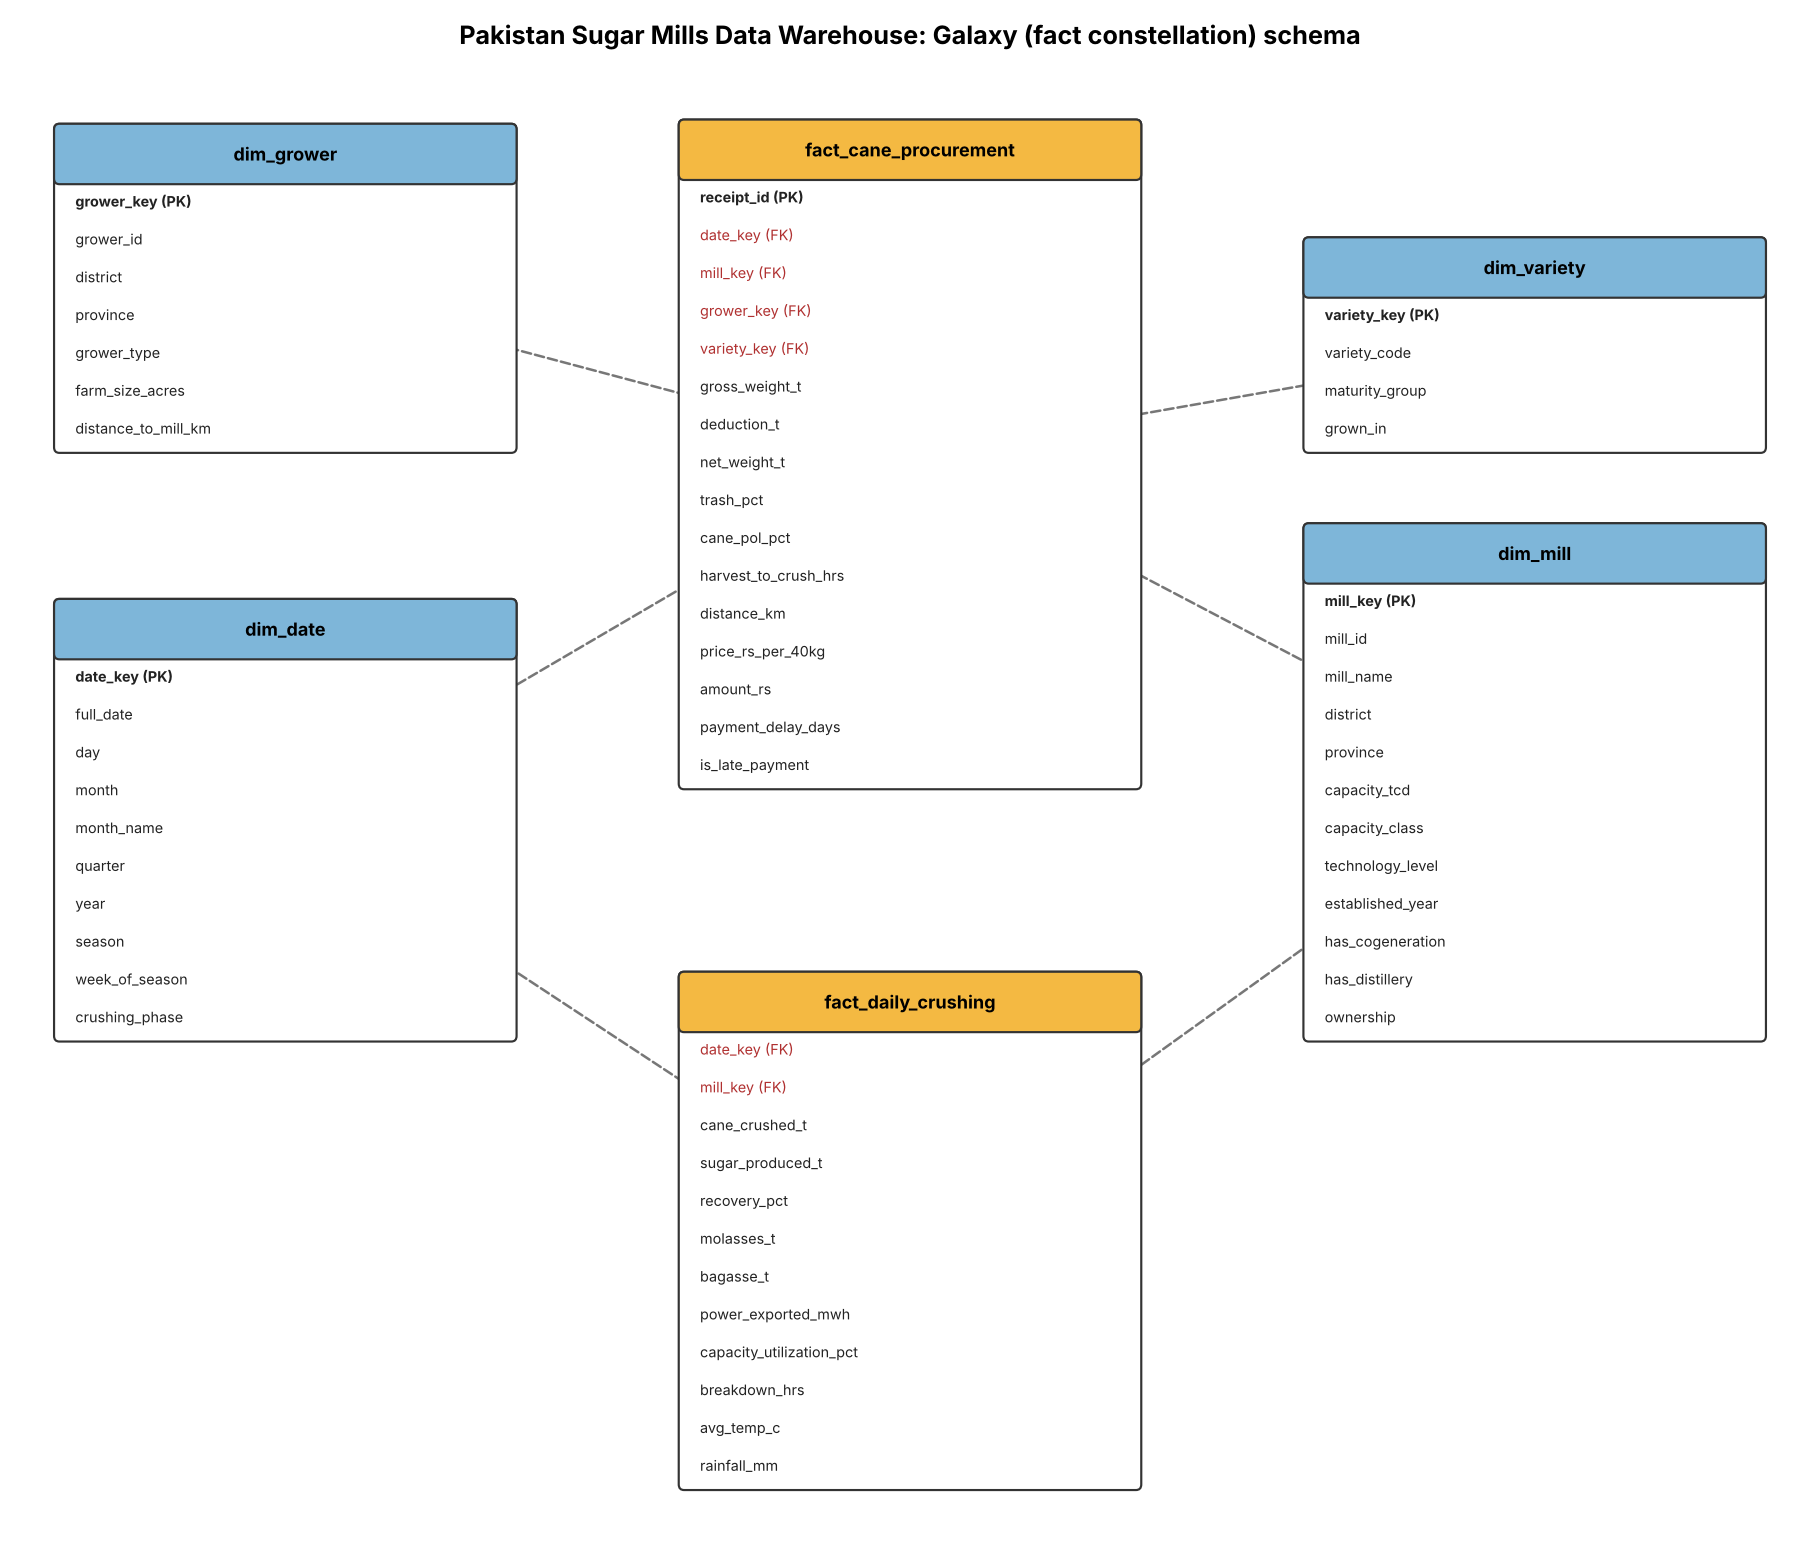

In [8]:
# Show the data warehouse schema diagram (saved in docs/star_schema.png)
from IPython.display import Image, display
display(Image(os.path.join(PROJECT_DIR, "docs", "star_schema.png"), width=900))

### 4.2 Build the dimensions

In [9]:
# ============================================================
# BUILD THE DIMENSION TABLES (the "who / what / when" of the warehouse)
# ============================================================
# ---- dim_date: every calendar day of the 10 crushing seasons ----
# sequence() creates a list of dates, explode() turns that list into one row per date.
dim_date = (spark.sql("SELECT explode(sequence(to_date('2015-10-01'), to_date('2025-06-30'), interval 1 day)) AS full_date")
    .withColumn("date_key", F.date_format("full_date", "yyyyMMdd").cast("int"))   # surrogate key, e.g. 20250115
    .withColumn("day", F.dayofmonth("full_date"))
    .withColumn("month", F.month("full_date"))
    .withColumn("month_name", F.date_format("full_date", "MMM"))                  # Jan, Feb, ...
    .withColumn("quarter", F.quarter("full_date"))
    .withColumn("year", F.year("full_date"))
    # A crushing season runs Nov to Apr, so Jan 2025 belongs to season "2024-25". season_start is the first year.
    .withColumn("season_start", F.when(F.col("month") >= 7, F.col("year")).otherwise(F.col("year") - 1))
    .withColumn("season", F.concat(F.col("season_start"), F.lit("-"),
                                   F.lpad(((F.col("season_start") + 1) % 100).cast("string"), 2, "0")))
    # Week number counted from 1 November of the season
    .withColumn("week_of_season", F.floor(F.datediff("full_date", F.make_date("season_start", F.lit(11), F.lit(1))) / 7) + 1)
    # Group months into phases of the crushing season (used in OLAP queries)
    .withColumn("crushing_phase", F.when(F.col("month").isin(11, 12), "Early (Nov-Dec)")
                                   .when(F.col("month").isin(1, 2), "Peak (Jan-Feb)")
                                   .when(F.col("month").isin(3, 4, 5), "Late (Mar-May)")
                                   .otherwise("Off-season"))
    .drop("season_start"))           # helper column no longer needed

# ---- dim_mill ----
# row_number() gives each mill a simple integer surrogate key (1, 2, 3, ...).
dim_mill = (mills_src
    .withColumn("mill_key", F.row_number().over(Window.orderBy("mill_id")))
    .withColumn("capacity_class", F.when(F.col("capacity_tcd") < 7000, "Small (<7k TCD)")       # TCD = tonnes of cane per day
                                   .when(F.col("capacity_tcd") < 12000, "Medium (7-12k TCD)")
                                   .otherwise("Large (12k+ TCD)")))

# ---- dim_grower ----
dim_grower = growers_src.withColumn("grower_key", F.row_number().over(Window.orderBy("grower_id")))

# ---- dim_variety (+ an 'Unknown' member for unrecorded varieties) ----
# Fact rows with a missing variety point to this "Unknown" row, so no fact row is lost in the join.
unknown = spark.createDataFrame([("Unknown", "Unknown", "Unknown")], varieties_src.columns)
dim_variety = (varieties_src.unionByName(unknown)
    .withColumn("variety_key", F.row_number().over(Window.orderBy("variety_code"))))

for n, d in [("dim_date", dim_date), ("dim_mill", dim_mill), ("dim_grower", dim_grower), ("dim_variety", dim_variety)]:
    print(f"{n:<12} {d.count():>8,} rows")
dim_mill.show(5)

dim_date        3,561 rows
dim_mill           85 rows
dim_grower     85,867 rows


dim_variety        12 rows
+-------+-----------------+--------+--------------+------------+----------------+----------------+----------------+--------------+----------+--------+------------------+
|mill_id|        mill_name|province|      district|capacity_tcd|technology_level|established_year|has_cogeneration|has_distillery| ownership|mill_key|    capacity_class|
+-------+-----------------+--------+--------------+------------+----------------+----------------+----------------+--------------+----------+--------+------------------+
|   M001|PB-Sugar-Mill-001|  Punjab|Rahim Yar Khan|       10100|        Standard|            2000|               1|             0|   Private|       1|Medium (7-12k TCD)|
|   M002|PB-Sugar-Mill-002|  Punjab|Rahim Yar Khan|       12600|        Standard|            1998|               0|             0|PSX Listed|       2|  Large (12k+ TCD)|
|   M003|PB-Sugar-Mill-003|  Punjab|Rahim Yar Khan|        8800|             Old|            1952|               0|        

### 4.3 Build the fact tables (lookup surrogate keys with broadcast joins)

In [10]:
# ============================================================
# BUILD THE FACT TABLES (the measurable events)
# ============================================================
# Replace natural keys (mill_id, grower_id, variety_code) with the integer surrogate keys from the dimensions.
# F.broadcast copies the small dimension table to every worker, so the ~1M-row table never has to be shuffled.
fact_cane_procurement = (proc
    .join(F.broadcast(dim_mill.select("mill_id", "mill_key")), "mill_id")
    .join(F.broadcast(dim_grower.select("grower_id", "grower_key")), "grower_id")
    .join(F.broadcast(dim_variety.select("variety_code", "variety_key")), "variety_code")
    .withColumn("date_key", F.date_format("receipt_date", "yyyyMMdd").cast("int"))   # same format as dim_date.date_key
    # keep only keys + measures (descriptive text now lives in the dimensions)
    .select("receipt_id", "date_key", "mill_key", "grower_key", "variety_key", "season", "receipt_hour",
            "transport_mode", "payment_mode", "distance_km", "harvest_to_crush_hrs", "gross_weight_t",
            "trash_pct", "deduction_t", "net_weight_t", "cane_pol_pct", "price_rs_per_40kg", "amount_rs",
            "payment_delay_days", "is_late_payment"))

# Second fact table: one row per mill per crushing day
fact_daily_crushing = (daily
    .join(F.broadcast(dim_mill.select("mill_id", "mill_key")), "mill_id")
    .withColumn("date_key", F.date_format("date", "yyyyMMdd").cast("int"))
    .select("date_key", "mill_key", "season", "crushing_day", "cane_crushed_t", "sugar_produced_t",
            "recovery_pct", "pol_pct_cane", "fiber_pct", "molasses_t", "bagasse_t", "power_exported_mwh",
            "capacity_utilization_pct", "breakdown_hrs", "operating_hrs", "avg_temp_c", "rainfall_mm"))

# referential integrity check: no fact row lost in the key lookup
# (if a key were missing from a dimension, the inner join would silently drop that row)
print("procurement rows:", n_clean, "-> fact rows:", fact_cane_procurement.count())
print("daily rows      :", daily.count(), "-> fact rows:", fact_daily_crushing.count())

procurement rows: 978522 -> fact rows: 978522


daily rows      : 85431 -> fact rows: 85431


### 4.4 Load: write the warehouse as Parquet, partitioned by season
Columnar **Parquet** with **partitioning** is the standard storage layout for analytical big data: queries read only the columns
and seasons they need (column pruning + partition pruning).

In [11]:
# ============================================================
# LOAD: save the warehouse to disk as Parquet files
# ============================================================
t0 = time.time()
# repartition("season") puts each season's rows together -> one file per season folder.
# zstd = a strong compression codec. partitionBy("season") creates folders like season=2024-25/.
(fact_cane_procurement.repartition("season").write.mode("overwrite").option("compression", "zstd")
 .partitionBy("season").parquet(f"{WAREHOUSE}/fact_cane_procurement"))
(fact_daily_crushing.repartition("season").write.mode("overwrite").option("compression", "zstd")
 .partitionBy("season").parquet(f"{WAREHOUSE}/fact_daily_crushing"))
# Dimensions are small, so they are saved without partitioning.
for n, d in [("dim_date", dim_date), ("dim_mill", dim_mill), ("dim_grower", dim_grower), ("dim_variety", dim_variety)]:
    d.write.mode("overwrite").parquet(f"{WAREHOUSE}/{n}")
print(f"Warehouse written in {time.time()-t0:.1f} s")

# Helper: total size of all files inside a folder, in MB
def folder_mb(path):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 1e6
print(f"Procurement as CSV.gz : {folder_mb(f'{DATA}/synthetic/cane_procurement'):6.1f} MB")
print(f"Procurement as Parquet: {folder_mb(f'{WAREHOUSE}/fact_cane_procurement'):6.1f} MB")
print("Season partitions:", [d for d in sorted(os.listdir(f"{WAREHOUSE}/fact_cane_procurement")) if d.startswith("season=")])

Warehouse written in 9.8 s
Procurement as CSV.gz :   34.6 MB
Procurement as Parquet:   24.1 MB
Season partitions: ['season=2015-16', 'season=2016-17', 'season=2017-18', 'season=2018-19', 'season=2019-20', 'season=2020-21', 'season=2021-22', 'season=2022-23', 'season=2023-24', 'season=2024-25']


In [12]:
# Re-open the warehouse and register SQL views
# A temp view lets us query a DataFrame with normal SQL, e.g. SELECT ... FROM fact_daily_crushing
for t in ["fact_cane_procurement", "fact_daily_crushing", "dim_date", "dim_mill", "dim_grower", "dim_variety"]:
    spark.read.parquet(f"{WAREHOUSE}/{t}").createOrReplaceTempView(t)

# Benchmark: the same aggregation on raw CSV vs the Parquet warehouse
# (lambda = a tiny function we can call later; collect() forces Spark to actually run the query)
q_csv = lambda: (spark.read.csv(f"{DATA}/synthetic/cane_procurement/*.csv.gz", header=True, schema=procurement_schema)
                 .filter(F.col("season") == "2024-25").groupBy("transport_mode").agg(F.avg("net_weight_t")).collect())
q_parquet = lambda: spark.sql("SELECT transport_mode, avg(net_weight_t) FROM fact_cane_procurement "
                              "WHERE season = '2024-25' GROUP BY transport_mode").collect()
for name, q in [("CSV.gz", q_csv), ("Parquet", q_parquet)]:
    t0 = time.time(); q(); print(f"{name:<8} query time: {time.time()-t0:5.2f} s")
# explain() prints Spark's execution plan: look for PartitionFilters (only one season folder is read)
# and ReadSchema (only the 2 needed columns are read).
spark.sql("SELECT transport_mode, avg(net_weight_t) FROM fact_cane_procurement WHERE season='2024-25' GROUP BY transport_mode").explain()

CSV.gz   query time:  0.97 s


Parquet  query time:  0.40 s
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[transport_mode#8035], functions=[avg(net_weight_t#8042)])
   +- Exchange hashpartitioning(transport_mode#8035, 16), ENSURE_REQUIREMENTS, [plan_id=3130]
      +- HashAggregate(keys=[transport_mode#8035], functions=[partial_avg(net_weight_t#8042)])
         +- Project [transport_mode#8035, net_weight_t#8042]
            +- FileScan parquet [transport_mode#8035,net_weight_t#8042,season#8048] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/home/claude/pakistan-sugar-mills-analytics/warehouse/fact_cane_p..., PartitionFilters: [isnotnull(season#8048), (season#8048 = 2024-25)], PushedFilters: [], ReadSchema: struct<transport_mode:string,net_weight_t:double>




The physical plan shows `PartitionFilters: [isnotnull(season), (season = 2024-25)]` and a reduced `ReadSchema`:
Spark skips the other nine seasons and every unused column.

## 5. OLAP operations with Spark SQL

### 5.1 Roll-up: sugar production from mill → district → province → national (season 2024-25)
`GROUP BY ROLLUP` produces subtotals at every level of the geography hierarchy (rows with `null` are the subtotals).

In [13]:
# ROLL-UP: GROUP BY ROLLUP(province, district) returns totals per district, subtotals per province
# and one grand total (rows where province/district is null are the subtotals).
# recovery % = total sugar / total cane x 100 (a weighted average, more correct than averaging percentages).
rollup = spark.sql('''
SELECT m.province, m.district,
       ROUND(SUM(f.cane_crushed_t)/1e6, 2)   AS cane_crushed_mt,
       ROUND(SUM(f.sugar_produced_t)/1e3, 1) AS sugar_000t,
       ROUND(SUM(f.sugar_produced_t) / SUM(f.cane_crushed_t) * 100, 2) AS recovery_pct
FROM fact_daily_crushing f JOIN dim_mill m ON f.mill_key = m.mill_key
WHERE f.season = '2024-25'
GROUP BY ROLLUP (m.province, m.district)
ORDER BY m.province NULLS LAST, m.district NULLS FIRST
''').toPandas()
rollup.fillna("ALL").head(40)    # show the null subtotal labels as "ALL"

,province,district,cane_crushed_mt,sugar_000t,recovery_pct
0,KPK,ALL,2.16,194.6,9.00
1,KPK,Charsadda,0.45,40.7,9.13
2,KPK,Dera Ismail Khan,0.98,86.7,8.89
3,KPK,Mardan,0.35,30.5,8.70
4,KPK,Peshawar,0.39,36.7,9.41
5,Punjab,ALL,51.33,5007.4,9.76
6,Punjab,Bahawalpur,0.90,90.1,10.00
7,Punjab,Bhakkar,1.02,98.3,9.63
8,Punjab,Chiniot,2.63,259.3,9.86
9,Punjab,Dera Ghazi Khan,1.25,120.8,9.64


### 5.2 Cube: recovery % across every combination of province and crushing phase

In [14]:
# CUBE: aggregates for EVERY combination of the listed dimensions
# (province x phase, province only, phase only, and the grand total).
cube = spark.sql('''
SELECT COALESCE(m.province, 'ALL') AS province, COALESCE(d.crushing_phase, 'ALL') AS phase,
       ROUND(SUM(f.sugar_produced_t) / SUM(f.cane_crushed_t) * 100, 2) AS recovery_pct
FROM fact_daily_crushing f
JOIN dim_mill m ON f.mill_key = m.mill_key
JOIN dim_date d ON f.date_key = d.date_key
GROUP BY CUBE (m.province, d.crushing_phase)
''').toPandas()
# Reshape into a grid: rows = province, columns = phase
cube_pivot = cube.pivot(index="province", columns="phase", values="recovery_pct")
cube_pivot = cube_pivot[["Early (Nov-Dec)", "Peak (Jan-Feb)", "Late (Mar-May)", "ALL"]]   # put the columns in season order
cube_pivot

phase,Early (Nov-Dec),Peak (Jan-Feb),Late (Mar-May),ALL
province,,,,
ALL,9.68,10.09,9.31,9.77
KPK,8.97,9.62,NaN,8.97
Punjab,9.69,10.03,9.30,9.71
Sindh,9.87,10.25,10.26,10.05


### 5.3 Slice and dice
* **Slice** = fix one dimension (season = 2022-23, the flood year).
* **Dice** = select a sub-cube on several dimensions (Sindh × Modern mills × Jan-Feb).

In [15]:
# SLICE: fix ONE dimension to a single value (season = 2022-23) and compare mills by technology level.
slice_q = spark.sql('''
SELECT m.technology_level, COUNT(DISTINCT m.mill_key) AS mills,
       ROUND(AVG(f.recovery_pct), 2) AS avg_recovery, ROUND(AVG(f.capacity_utilization_pct), 1) AS avg_utilization,
       ROUND(SUM(f.breakdown_hrs) / COUNT(DISTINCT m.mill_key), 1) AS breakdown_hrs_per_mill
FROM fact_daily_crushing f JOIN dim_mill m ON f.mill_key = m.mill_key
WHERE f.season = '2022-23'
GROUP BY m.technology_level ORDER BY avg_recovery DESC''').toPandas()
print("SLICE: season 2022-23"); display(slice_q)

# DICE: filter on SEVERAL dimensions at once (province AND technology AND months) to get a smaller sub-cube.
dice_q = spark.sql('''
SELECT d.season, ROUND(AVG(f.recovery_pct), 2) AS avg_recovery, ROUND(SUM(f.sugar_produced_t)/1e3, 1) AS sugar_000t
FROM fact_daily_crushing f
JOIN dim_mill m ON f.mill_key = m.mill_key
JOIN dim_date d ON f.date_key = d.date_key
WHERE m.province = 'Sindh' AND m.technology_level = 'Modern' AND d.month IN (1, 2)
GROUP BY d.season ORDER BY d.season''').toPandas()
print("DICE: Sindh x Modern mills x January-February"); display(dice_q)

SLICE: season 2022-23


,technology_level,mills,avg_recovery,avg_utilization,breakdown_hrs_per_mill
0,Modern,26,9.75,96.1,21.3
1,Standard,38,9.44,92.1,58.8
2,Old,18,9.01,77.9,96.4


DICE: Sindh x Modern mills x January-February


,season,avg_recovery,sugar_000t
0,2015-16,10.87,301.2
1,2016-17,10.73,483.9
2,2017-18,9.42,411.8
3,2018-19,11.29,367.9
4,2019-20,10.39,286.1
5,2020-21,10.52,421.8
6,2021-22,10.50,490.6
7,2022-23,10.32,209.3
8,2023-24,10.61,206.0
9,2024-25,10.61,187.1


### 5.4 Drill-down: season → month → week (Punjab, 2024-25)

In [16]:
# DRILL-DOWN: move from a summary level to a more detailed level of the date hierarchy.
# Level 1: sugar per month (the CASE puts Nov and Dec before Jan so months appear in season order)
by_month = spark.sql('''
SELECT d.month, d.month_name, ROUND(SUM(f.sugar_produced_t)/1e3, 1) AS sugar_000t, ROUND(AVG(f.recovery_pct), 2) AS recovery
FROM fact_daily_crushing f JOIN dim_mill m USING (mill_key) JOIN dim_date d USING (date_key)
WHERE m.province = 'Punjab' AND f.season = '2024-25'
GROUP BY d.month, d.month_name ORDER BY CASE WHEN d.month >= 7 THEN d.month - 12 ELSE d.month END''').toPandas()
# Level 2: drill into January and look at each week
by_week = spark.sql('''
SELECT d.week_of_season, ROUND(SUM(f.sugar_produced_t)/1e3, 1) AS sugar_000t, ROUND(AVG(f.recovery_pct), 2) AS recovery
FROM fact_daily_crushing f JOIN dim_mill m USING (mill_key) JOIN dim_date d USING (date_key)
WHERE m.province = 'Punjab' AND f.season = '2024-25' AND d.month = 1
GROUP BY d.week_of_season ORDER BY d.week_of_season''').toPandas()
print("Level 1 (month):"); display(by_month)
print("Level 2 (weeks of January):"); display(by_week)

Level 1 (month):


,month,month_name,sugar_000t,recovery
0,11,Nov,118.0,9.42
1,12,Dec,1036.6,9.75
2,1,Jan,1097.4,10.06
3,2,Feb,983.6,10.05
4,3,Mar,1050.1,9.60
5,4,Apr,719.4,8.93
6,5,May,2.3,8.67


Level 2 (weeks of January):


,week_of_season,sugar_000t,recovery
0,9,68.7,9.93
1,10,246.7,9.97
2,11,247.8,10.04
3,12,250.7,10.12
4,13,247.2,10.14
5,14,36.4,10.13


### 5.5 Pivot: sugar produced ('000 t) by season × province

In [17]:
# PIVOT (with the DataFrame API instead of SQL): seasons become rows, provinces become columns.
pivot = (spark.table("fact_daily_crushing").join(spark.table("dim_mill"), "mill_key")
         .groupBy("season").pivot("province", ["Punjab", "Sindh", "KPK"])     # listing the values makes pivot faster
         .agg(F.round(F.sum("sugar_produced_t") / 1e3, 0)).orderBy("season").toPandas().set_index("season"))
pivot["Total"] = pivot.sum(axis=1)     # add a national total column
pivot

,Punjab,Sindh,KPK,Total
season,,,,
2015-16,3222.0,1696.0,223.0,5141.0
2016-17,4557.0,2332.0,280.0,7169.0
2017-18,3697.0,1746.0,271.0,5714.0
2018-19,3439.0,1589.0,229.0,5257.0
2019-20,3080.0,1509.0,216.0,4805.0
2020-21,4323.0,1757.0,230.0,6310.0
2021-22,5459.0,2097.0,260.0,7816.0
2022-23,5072.0,1394.0,197.0,6663.0
2023-24,5231.0,1433.0,204.0,6868.0


### 5.6 Window functions: top 3 mills by recovery in each season, and grower payment compliance

In [18]:
# WINDOW FUNCTION: RANK() OVER (PARTITION BY season ...) ranks mills separately inside each season.
# The outer query keeps only ranks 1-3, i.e. the top 3 mills by recovery in every season.
top3 = spark.sql('''
SELECT * FROM (
  SELECT f.season, m.mill_name, m.province, m.technology_level,
         ROUND(SUM(f.sugar_produced_t) / SUM(f.cane_crushed_t) * 100, 2) AS recovery_pct,
         RANK() OVER (PARTITION BY f.season ORDER BY SUM(f.sugar_produced_t) / SUM(f.cane_crushed_t) DESC) AS rnk
  FROM fact_daily_crushing f JOIN dim_mill m ON f.mill_key = m.mill_key
  GROUP BY f.season, m.mill_name, m.province, m.technology_level)
WHERE rnk <= 3 ORDER BY season, rnk''').toPandas()
display(top3.tail(9))       # last 3 seasons

# Share of late payments: the average of a 0/1 column = the fraction of 1s (x100 = percent)
late = spark.sql('''
SELECT f.season, m.province, ROUND(AVG(f.is_late_payment) * 100, 1) AS pct_late
FROM fact_cane_procurement f JOIN dim_mill m ON f.mill_key = m.mill_key
GROUP BY f.season, m.province''').toPandas().pivot(index="season", columns="province", values="pct_late")
print("% of receipts paid after 15 days"); display(late)

,season,mill_name,province,technology_level,recovery_pct,rnk
21,2022-23,SD-Sugar-Mill-068,Sindh,Modern,10.69,1
22,2022-23,SD-Sugar-Mill-048,Sindh,Modern,10.52,2
23,2022-23,SD-Sugar-Mill-059,Sindh,Modern,10.36,3
24,2023-24,SD-Sugar-Mill-068,Sindh,Modern,11.00,1
25,2023-24,SD-Sugar-Mill-048,Sindh,Modern,10.72,2
26,2023-24,SD-Sugar-Mill-059,Sindh,Modern,10.59,3
27,2024-25,SD-Sugar-Mill-068,Sindh,Modern,10.98,1
28,2024-25,SD-Sugar-Mill-048,Sindh,Modern,10.81,2
29,2024-25,SD-Sugar-Mill-059,Sindh,Modern,10.56,3


% of receipts paid after 15 days


province,KPK,Punjab,Sindh
season,,,
2015-16,23.6,19.9,45.0
2016-17,19.8,23.7,45.7
2017-18,62.1,65.4,85.4
2018-19,65.1,64.0,85.8
2019-20,23.1,19.0,50.0
2020-21,20.0,21.7,48.4
2021-22,19.7,23.7,45.4
2022-23,59.8,65.1,88.9
2023-24,61.5,64.9,88.7


## 6. Big data analytics and visualisation
Aggregations run in Spark over all ~980,000 receipts; only the small aggregated results are brought to pandas for plotting.

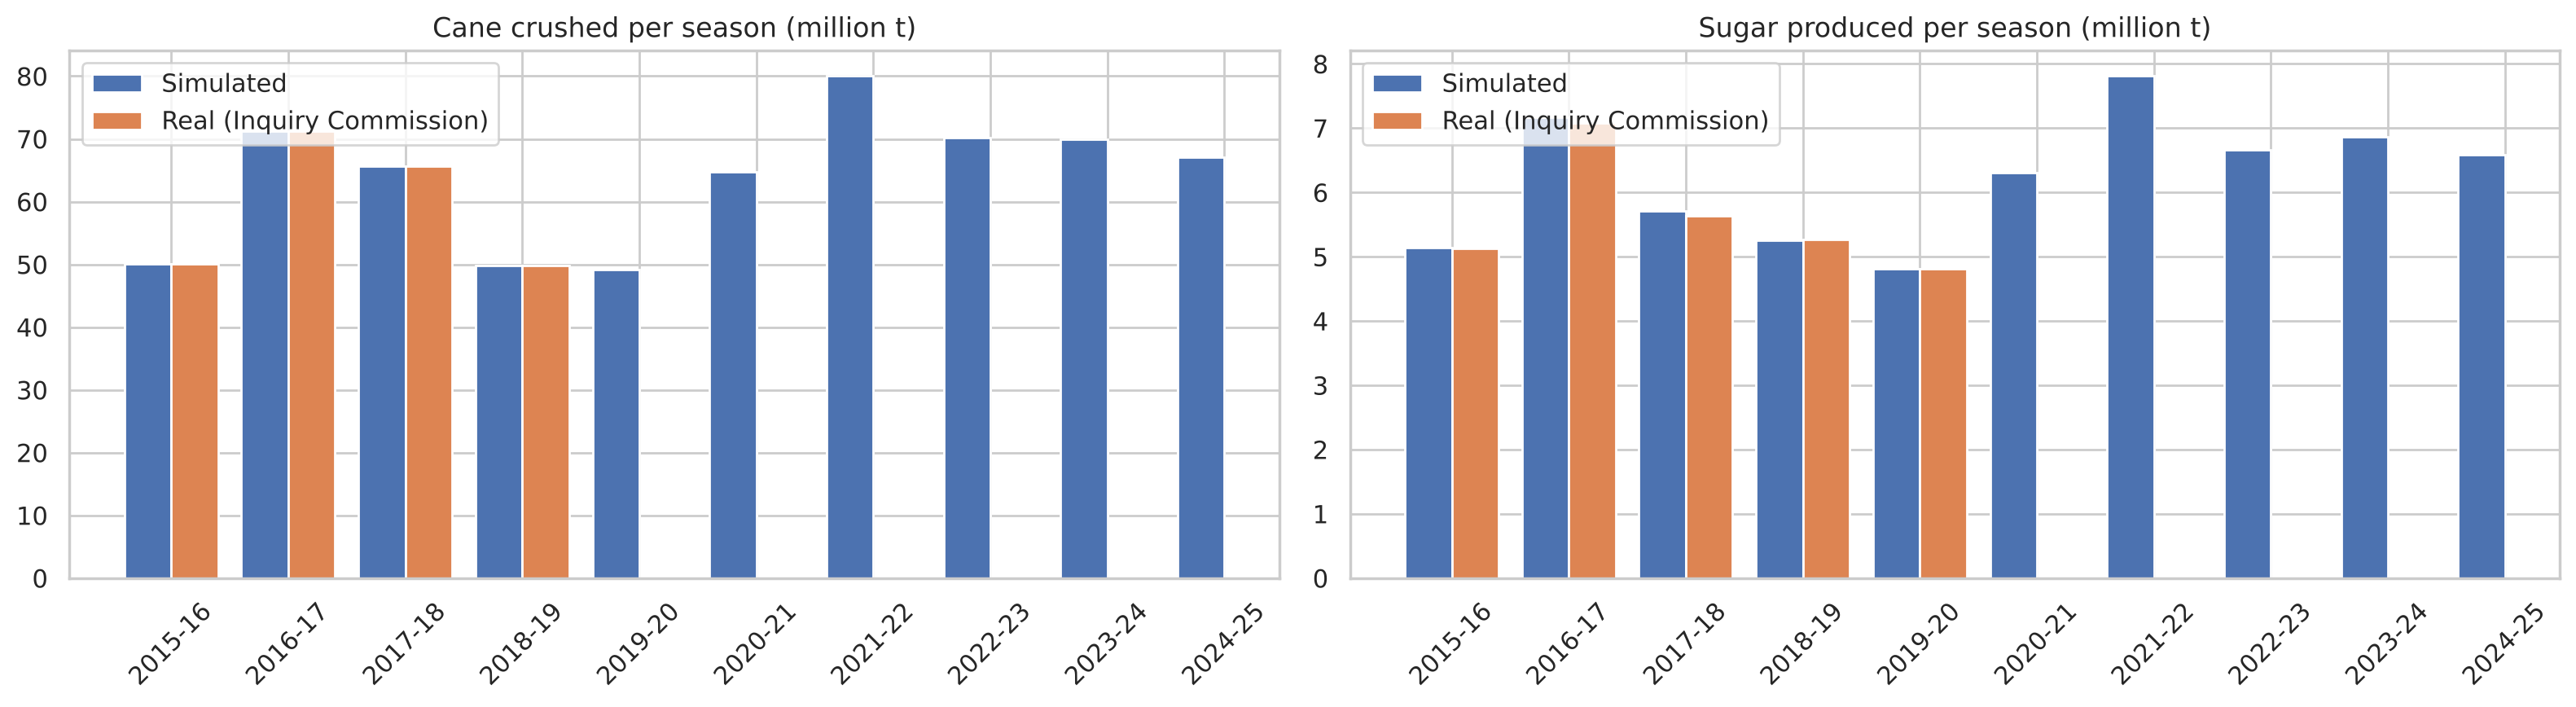

,season,sim_crushed_mt,sim_sugar_mt,cane_crushed_mt,sugar_produced_mt,source
0,2015-16,50.03,5.14,50.06,5.12,Sugar Inquiry Commission Report 2020 (provinci...
1,2016-17,71.25,7.17,71.25,7.08,Sugar Inquiry Commission Report 2020 (provinci...
2,2017-18,65.67,5.71,65.67,5.63,Sugar Inquiry Commission Report 2020 (provinci...
3,2018-19,49.78,5.26,49.77,5.27,Sugar Inquiry Commission Report 2020 (provinci...
4,2019-20,49.12,4.81,NaN,4.81,Sugar Inquiry Commission Report 2020 (5.268 mi...
5,2020-21,64.81,6.31,NaN,NaN,NaN
6,2021-22,80.08,7.82,NaN,NaN,NaN
7,2022-23,70.14,6.66,NaN,NaN,NaN
8,2023-24,69.88,6.87,NaN,NaN,NaN
9,2024-25,67.14,6.58,NaN,NaN,NaN


In [19]:
# 6.1 Validation: simulated national totals vs the real published figures
# Spark sums the big table; only 10 rows (one per season) come back to pandas.
sim = (spark.table("fact_daily_crushing").groupBy("season")
       .agg((F.sum("cane_crushed_t")/1e6).alias("sim_crushed_mt"), (F.sum("sugar_produced_t")/1e6).alias("sim_sugar_mt"))
       .orderBy("season").toPandas())
val = sim.merge(real_nat, on="season", how="left")        # put simulated and real numbers side by side
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
x = np.arange(len(val))                                    # bar positions; -0.2 / +0.2 draws the two bars next to each other
ax[0].bar(x - 0.2, val.sim_crushed_mt, 0.4, label="Simulated")
ax[0].bar(x + 0.2, val.cane_crushed_mt, 0.4, label="Real (Inquiry Commission)")
ax[0].set_title("Cane crushed per season (million t)")
ax[1].bar(x - 0.2, val.sim_sugar_mt, 0.4, label="Simulated")
ax[1].bar(x + 0.2, val.sugar_produced_mt, 0.4, label="Real (Inquiry Commission)")
ax[1].set_title("Sugar produced per season (million t)")
for a in ax:
    a.set_xticks(x); a.set_xticklabels(val.season, rotation=45); a.legend()
savefig("02_validation_simulated_vs_real.png")
val.round(2)

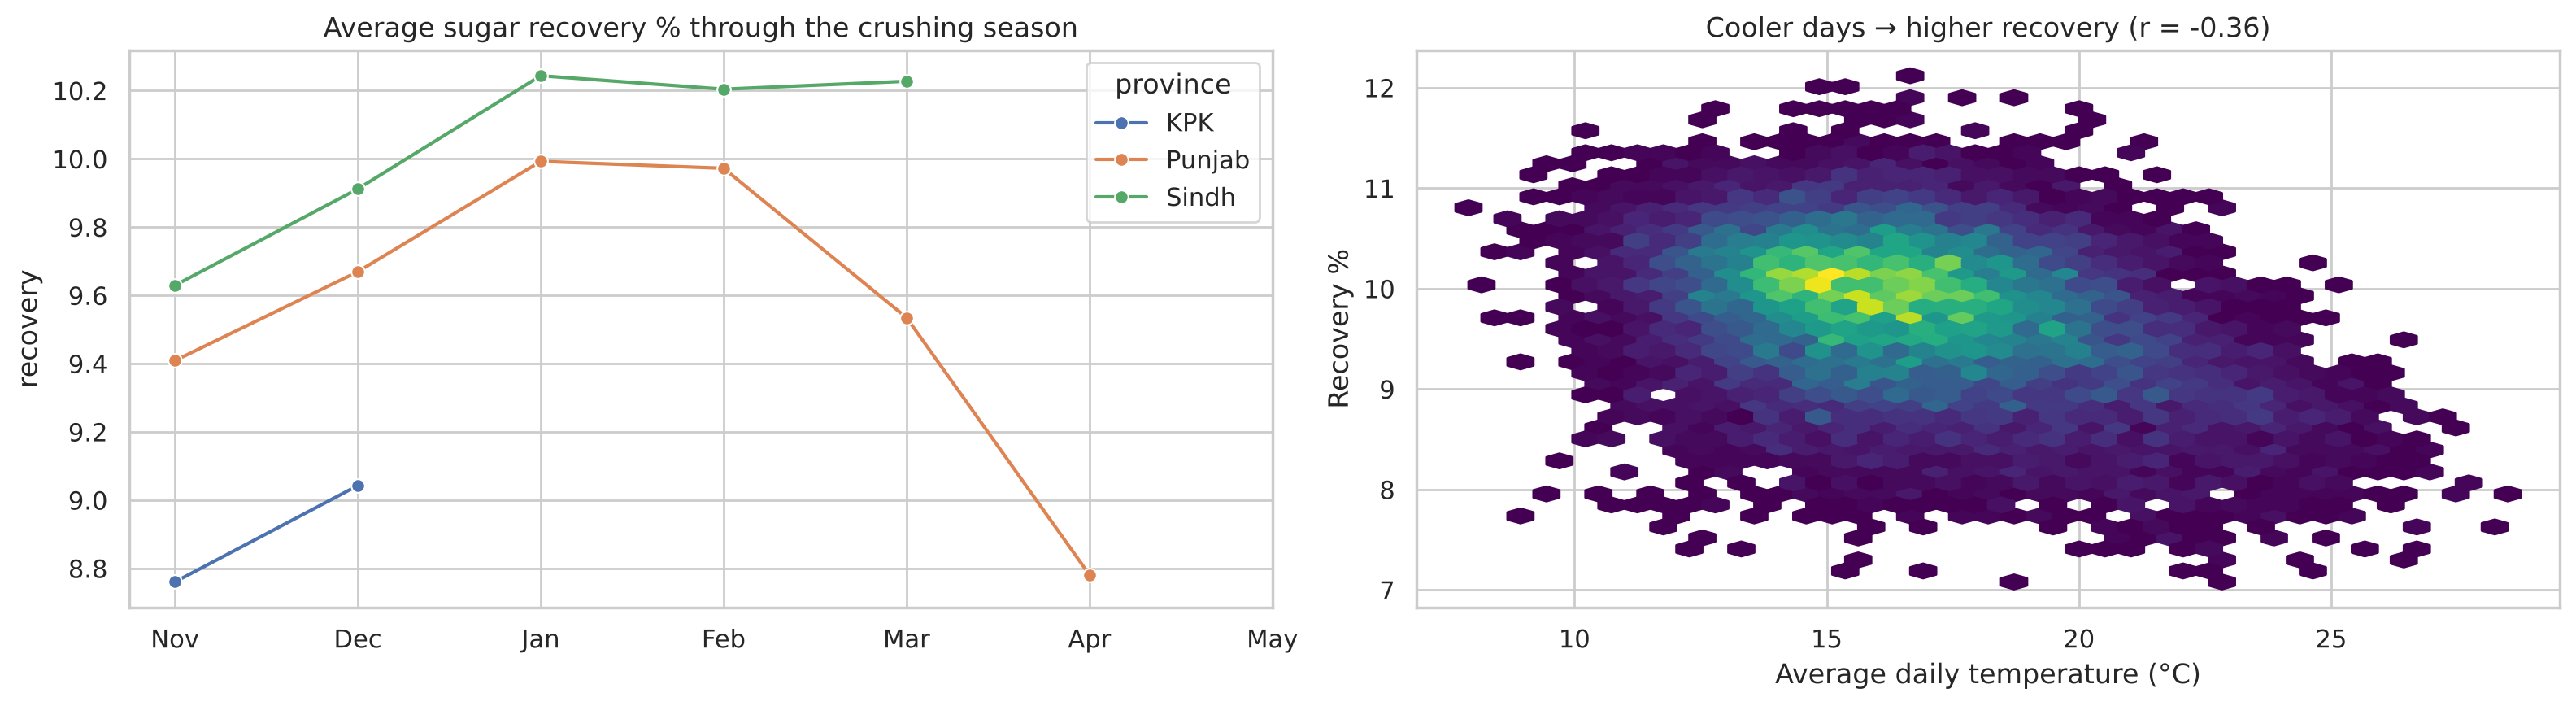

In [20]:
# 6.2 Recovery by month and province + daily recovery vs temperature
# Average recovery for every province-month combination (months with few mill-days are dropped).
rec_month = (spark.table("fact_daily_crushing").join(spark.table("dim_mill"), "mill_key")
             .join(spark.table("dim_date"), "date_key")
             .groupBy("province", "month").agg(F.avg("recovery_pct").alias("recovery"), F.count("*").alias("n"))
             .filter("n > 200").toPandas())
rec_month["order"] = rec_month.month.map({11: 0, 12: 1, 1: 2, 2: 3, 3: 4, 4: 5, 5: 6})   # Nov=0 ... May=6 for the x-axis
rec_month = rec_month.dropna().sort_values("order")
# sample(0.15) = take a random 15% so plotting stays fast (seed makes it repeatable)
temp_sample = spark.table("fact_daily_crushing").sample(0.15, seed=1).select("avg_temp_c", "recovery_pct").toPandas()

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
sns.lineplot(data=rec_month, x="order", y="recovery", hue="province", marker="o", ax=ax[0])
ax[0].set_xticks(range(7)); ax[0].set_xticklabels(["Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May"])
ax[0].set_title("Average sugar recovery % through the crushing season"); ax[0].set_xlabel("")
# hexbin = a density scatter plot (better than plain dots when there are thousands of points)
ax[1].hexbin(temp_sample.avg_temp_c, temp_sample.recovery_pct, gridsize=40, cmap="viridis", mincnt=1)
ax[1].set_xlabel("Average daily temperature (°C)"); ax[1].set_ylabel("Recovery %")
ax[1].set_title(f"Cooler days → higher recovery (r = {temp_sample.corr().iloc[0,1]:.2f})")   # r = correlation coefficient
savefig("03_recovery_patterns.png")

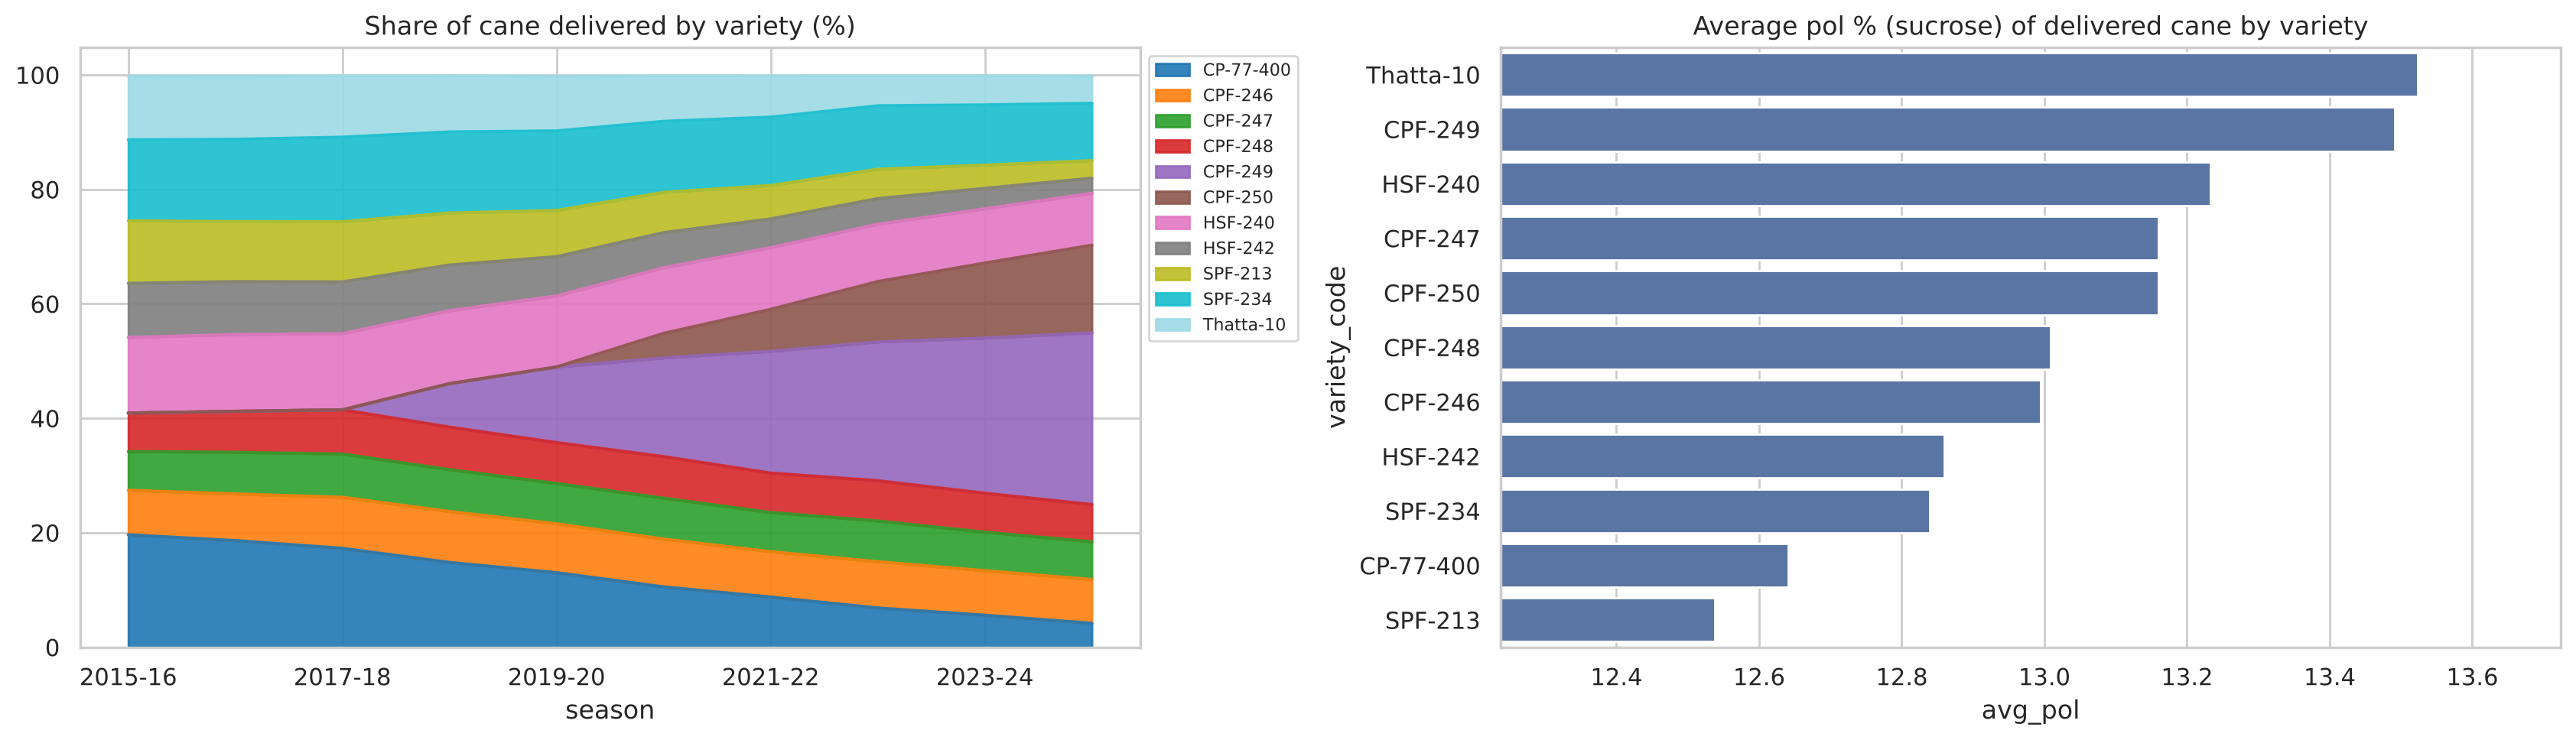

Highest-sucrose varieties in the data: ['Thatta-10', 'CPF-249', 'HSF-240', 'CPF-247']


In [21]:
# 6.3 Cane variety adoption and cane quality
# Share of each variety in each season: tonnes of variety / total tonnes of that season (window sum over season).
var_share = (spark.table("fact_cane_procurement").join(spark.table("dim_variety"), "variety_key")
             .groupBy("season", "variety_code").agg(F.sum("net_weight_t").alias("t"))
             .withColumn("share", F.col("t") / F.sum("t").over(Window.partitionBy("season")) * 100)
             .toPandas().pivot(index="season", columns="variety_code", values="share").fillna(0))
# Average pol % (sucrose) per variety, highest first
var_quality = (spark.table("fact_cane_procurement").join(spark.table("dim_variety"), "variety_key")
               .filter("variety_code != 'Unknown'").groupBy("variety_code")
               .agg(F.avg("cane_pol_pct").alias("avg_pol"), F.sum("net_weight_t").alias("tonnes"))
               .orderBy(F.desc("avg_pol")).toPandas())

fig, ax = plt.subplots(1, 2, figsize=(17, 5))
var_share.drop(columns=["Unknown"], errors="ignore").plot.area(ax=ax[0], cmap="tab20", alpha=0.9)   # stacked area chart
ax[0].set_title("Share of cane delivered by variety (%)"); ax[0].legend(bbox_to_anchor=(1, 1), fontsize=8)
sns.barplot(data=var_quality, y="variety_code", x="avg_pol", ax=ax[1], color="#4C72B0")
ax[1].set_xlim(var_quality.avg_pol.min() - 0.3, var_quality.avg_pol.max() + 0.2)   # zoom the axis so differences are visible
ax[1].set_title("Average pol % (sucrose) of delivered cane by variety")
savefig("04_varieties.png")
# Keep the 4 best varieties; this list is used as a feature in the regression model later.
TOP_VARIETIES = var_quality.variety_code.head(4).tolist()
print("Highest-sucrose varieties in the data:", TOP_VARIETIES)

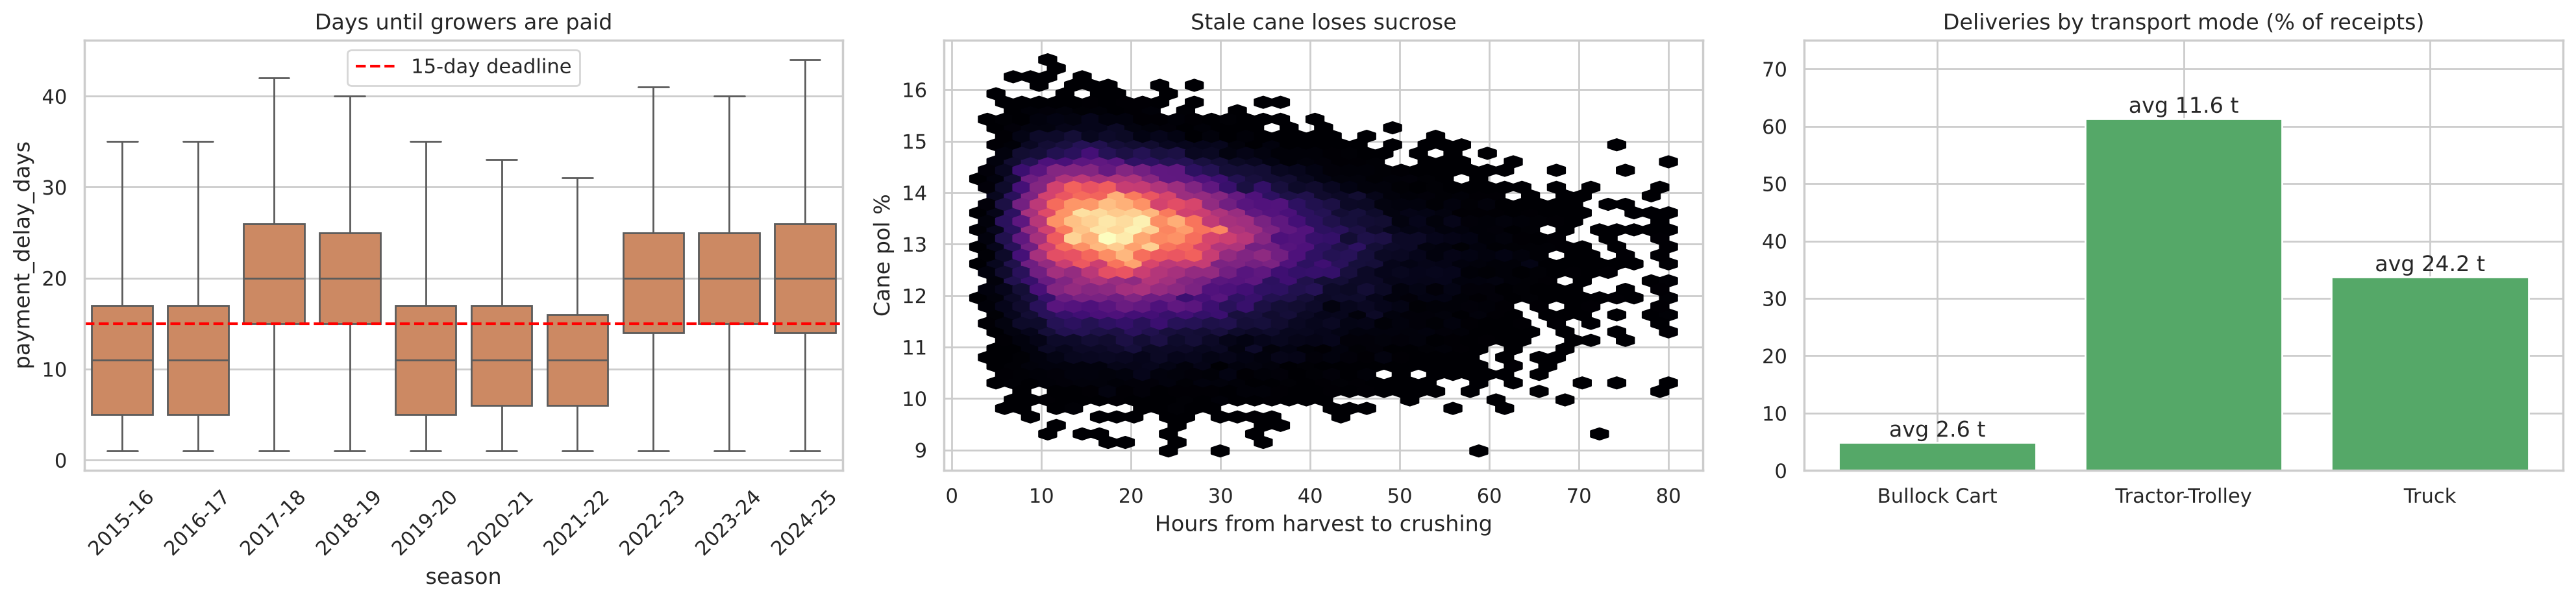

In [22]:
# 6.4 Grower side: payment delays, cane freshness, transport
# A 5% random sample (~50k rows) is plenty for charts and keeps pandas fast.
sample_pd = (spark.table("fact_cane_procurement").sample(0.05, seed=7)
             .select("season", "payment_delay_days", "harvest_to_crush_hrs", "cane_pol_pct", "transport_mode",
                     "net_weight_t").toPandas())
fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
# Chart 1: box plot of payment delay per season, with the 15-day deadline as a red line
sns.boxplot(data=sample_pd, x="season", y="payment_delay_days", ax=ax[0], showfliers=False, color="#DD8452",
            order=sorted(sample_pd.season.unique()))
ax[0].axhline(15, ls="--", c="red", label="15-day deadline"); ax[0].legend()
ax[0].tick_params(axis="x", rotation=45); ax[0].set_title("Days until growers are paid")
# Chart 2: the longer cane waits after harvest, the lower its sucrose (pol %)
ax[1].hexbin(sample_pd.harvest_to_crush_hrs.clip(0, 80), sample_pd.cane_pol_pct, gridsize=40, cmap="magma", mincnt=1)
ax[1].set_xlabel("Hours from harvest to crushing"); ax[1].set_ylabel("Cane pol %")
ax[1].set_title("Stale cane loses sucrose")
# Chart 3: share of deliveries by transport mode, with the average load written above each bar
tm = sample_pd.groupby("transport_mode").net_weight_t.agg(["count", "mean"])
ax[2].bar(tm.index, tm["count"] / tm["count"].sum() * 100, color="#55A868")
for i, (c, m) in enumerate(zip(tm["count"], tm["mean"])):
    ax[2].text(i, c / tm["count"].sum() * 100 + 1, f"avg {m:.1f} t", ha="center")
ax[2].set_ylim(0, 75); ax[2].set_title("Deliveries by transport mode (% of receipts)")
savefig("05_grower_side.png")

## 7. Machine learning 1: predicting daily sugar recovery % (regression)
**Business question:** given today's cane quality, weather and mill condition, what recovery will the mill achieve?
Mills use such forecasts to plan production and judge cane quality.

**Feature engineering (joining both fact tables):** the daily receipts at each mill are aggregated into
average cane pol %, trash %, harvest-to-crush hours and the share of the four highest-sucrose varieties,
then joined with weather, operations and mill attributes.

**Validation:** a *time-based split*: train on 2015-16 to 2022-23, test on the unseen seasons 2023-24 and 2024-25.
`pol_pct_cane` from the mill lab is excluded because it is measured from the same juice as recovery (target leakage).

In [23]:
# ============================================================
# ML 1: FEATURE ENGINEERING + TRAIN/TEST SPLIT for recovery prediction
# ============================================================
from pyspark.ml import Pipeline                                        # chains preprocessing + model into one object
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit

# Summarise each mill's receipts for each day: quality of cane that arrived that day.
rcpt_daily = (proc.groupBy("mill_id", F.col("receipt_date").alias("date"))
              .agg(F.avg("cane_pol_pct").alias("rcpt_avg_pol"), F.avg("trash_pct").alias("rcpt_avg_trash"),
                   F.avg("harvest_to_crush_hrs").alias("rcpt_avg_hrs"),
                   F.avg(F.col("variety_code").isin(TOP_VARIETIES).cast("int")).alias("share_top_varieties"),   # fraction of best varieties
                   F.count("*").alias("n_receipts")))

# Join mill-day operations + daily cane quality + mill attributes into one modelling table.
reg_df = (daily.join(rcpt_daily, ["mill_id", "date"])
          .join(F.broadcast(mills_src.select("mill_id", "province", "technology_level", "capacity_tcd", "has_cogeneration")), "mill_id")
          .withColumn("days_since_nov1", F.datediff("date", F.make_date(F.substring("season", 1, 4).cast("int"), F.lit(11), F.lit(1))))
          # sin/cos of the month turn the calendar into a circle, so the model knows December is next to January
          .withColumn("month_sin", F.sin(2 * np.pi * F.col("month") / 12))
          .withColumn("month_cos", F.cos(2 * np.pi * F.col("month") / 12)))

NUM = ["avg_temp_c", "rainfall_mm", "breakdown_hrs", "capacity_utilization_pct", "crushing_day", "days_since_nov1",
       "month_sin", "month_cos", "capacity_tcd", "has_cogeneration", "fiber_pct",
       "rcpt_avg_pol", "rcpt_avg_trash", "rcpt_avg_hrs", "share_top_varieties"]   # numeric input features
CAT = ["province", "technology_level"]                                           # text (categorical) features

# Time-based split: learn from older seasons, test on the 2 newest seasons the model has never seen.
train = reg_df.filter("season <= '2022-23'").cache()
test = reg_df.filter("season >= '2023-24'").cache()
print(f"train mill-days: {train.count():,} | test mill-days: {test.count():,}")

# Preprocessing steps (they will run inside the Pipeline):
indexers = [StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in CAT]   # text -> number (Punjab=0, Sindh=1 ...)
encoder = OneHotEncoder(inputCols=[c + "_idx" for c in CAT], outputCols=[c + "_ohe" for c in CAT]) # number -> 0/1 columns
assembler = VectorAssembler(inputCols=NUM + [c + "_ohe" for c in CAT], outputCol="raw_features")  # all features -> one vector column
scaler = StandardScaler(inputCol="raw_features", outputCol="features")                             # put features on a similar scale
prep = [*indexers, encoder, assembler, scaler]

train mill-days: 68,207 | test mill-days: 17,129


In [24]:
# Train 3 regression models and compare them on the unseen test seasons.
models = {
    "Linear Regression": LinearRegression(labelCol="recovery_pct", regParam=0.01),                    # simple baseline (straight-line relationships)
    "Random Forest": RandomForestRegressor(labelCol="recovery_pct", numTrees=80, maxDepth=10, seed=42),  # average of 80 decision trees
    "Gradient Boosted Trees": GBTRegressor(labelCol="recovery_pct", maxIter=80, maxDepth=5, stepSize=0.1, seed=42),  # trees built one after another, each fixing the previous errors
}
# Metrics: RMSE and MAE = average error in recovery points (lower is better); R2 = share of variation explained (1.0 is perfect)
ev = {m: RegressionEvaluator(labelCol="recovery_pct", metricName=m) for m in ["rmse", "mae", "r2"]}
reg_results, fitted = [], {}
for name, est in models.items():
    t0 = time.time()
    model = Pipeline(stages=prep + [est]).fit(train)     # run preprocessing + train the model on training seasons
    pred = model.transform(test)                         # predict on the test seasons (adds a "prediction" column)
    fitted[name] = model
    reg_results.append({"model": name, **{k.upper(): round(e.evaluate(pred), 4) for k, e in ev.items()},
                        "train_sec": round(time.time() - t0, 1)})
reg_results = pd.DataFrame(reg_results)
reg_results

,model,RMSE,MAE,R2,train_sec
0,Linear Regression,0.2591,0.2034,0.8029,7.3
1,Random Forest,0.2279,0.1786,0.8475,43.1
2,Gradient Boosted Trees,0.1905,0.1506,0.8934,86.9


**Hyper-parameter tuning** of the Random Forest with `TrainValidationSplit` (80/20 inside the training seasons):

In [25]:
# HYPER-PARAMETER TUNING: try 4 Random Forest settings and keep the one with the lowest validation RMSE.
rf = RandomForestRegressor(labelCol="recovery_pct", seed=42)
grid = ParamGridBuilder().addGrid(rf.numTrees, [40, 80]).addGrid(rf.maxDepth, [8, 12]).build()   # 2 x 2 = 4 combinations
# TrainValidationSplit: inside the training data, 80% trains each candidate and 20% scores it.
tvs = TrainValidationSplit(estimator=Pipeline(stages=prep + [rf]), estimatorParamMaps=grid,
                           evaluator=ev["rmse"], trainRatio=0.8, seed=42)
tvs_model = tvs.fit(train)
for params, metric in zip(grid, tvs_model.validationMetrics):      # print the score of every combination
    print({p.name: v for p, v in params.items()}, "-> validation RMSE", round(metric, 4))
best_rf = tvs_model.bestModel                                       # the winning combination, retrained on all training data
pred_tuned = best_rf.transform(test)
print("Tuned RF on test seasons: RMSE =", round(ev["rmse"].evaluate(pred_tuned), 4), "| R2 =", round(ev["r2"].evaluate(pred_tuned), 4))

{'numTrees': 40, 'maxDepth': 8} -> validation RMSE 0.2759
{'numTrees': 40, 'maxDepth': 12} -> validation RMSE 0.2358
{'numTrees': 80, 'maxDepth': 8} -> validation RMSE 0.276
{'numTrees': 80, 'maxDepth': 12} -> validation RMSE 0.2355


Tuned RF on test seasons: RMSE = 0.2169 | R2 = 0.8619


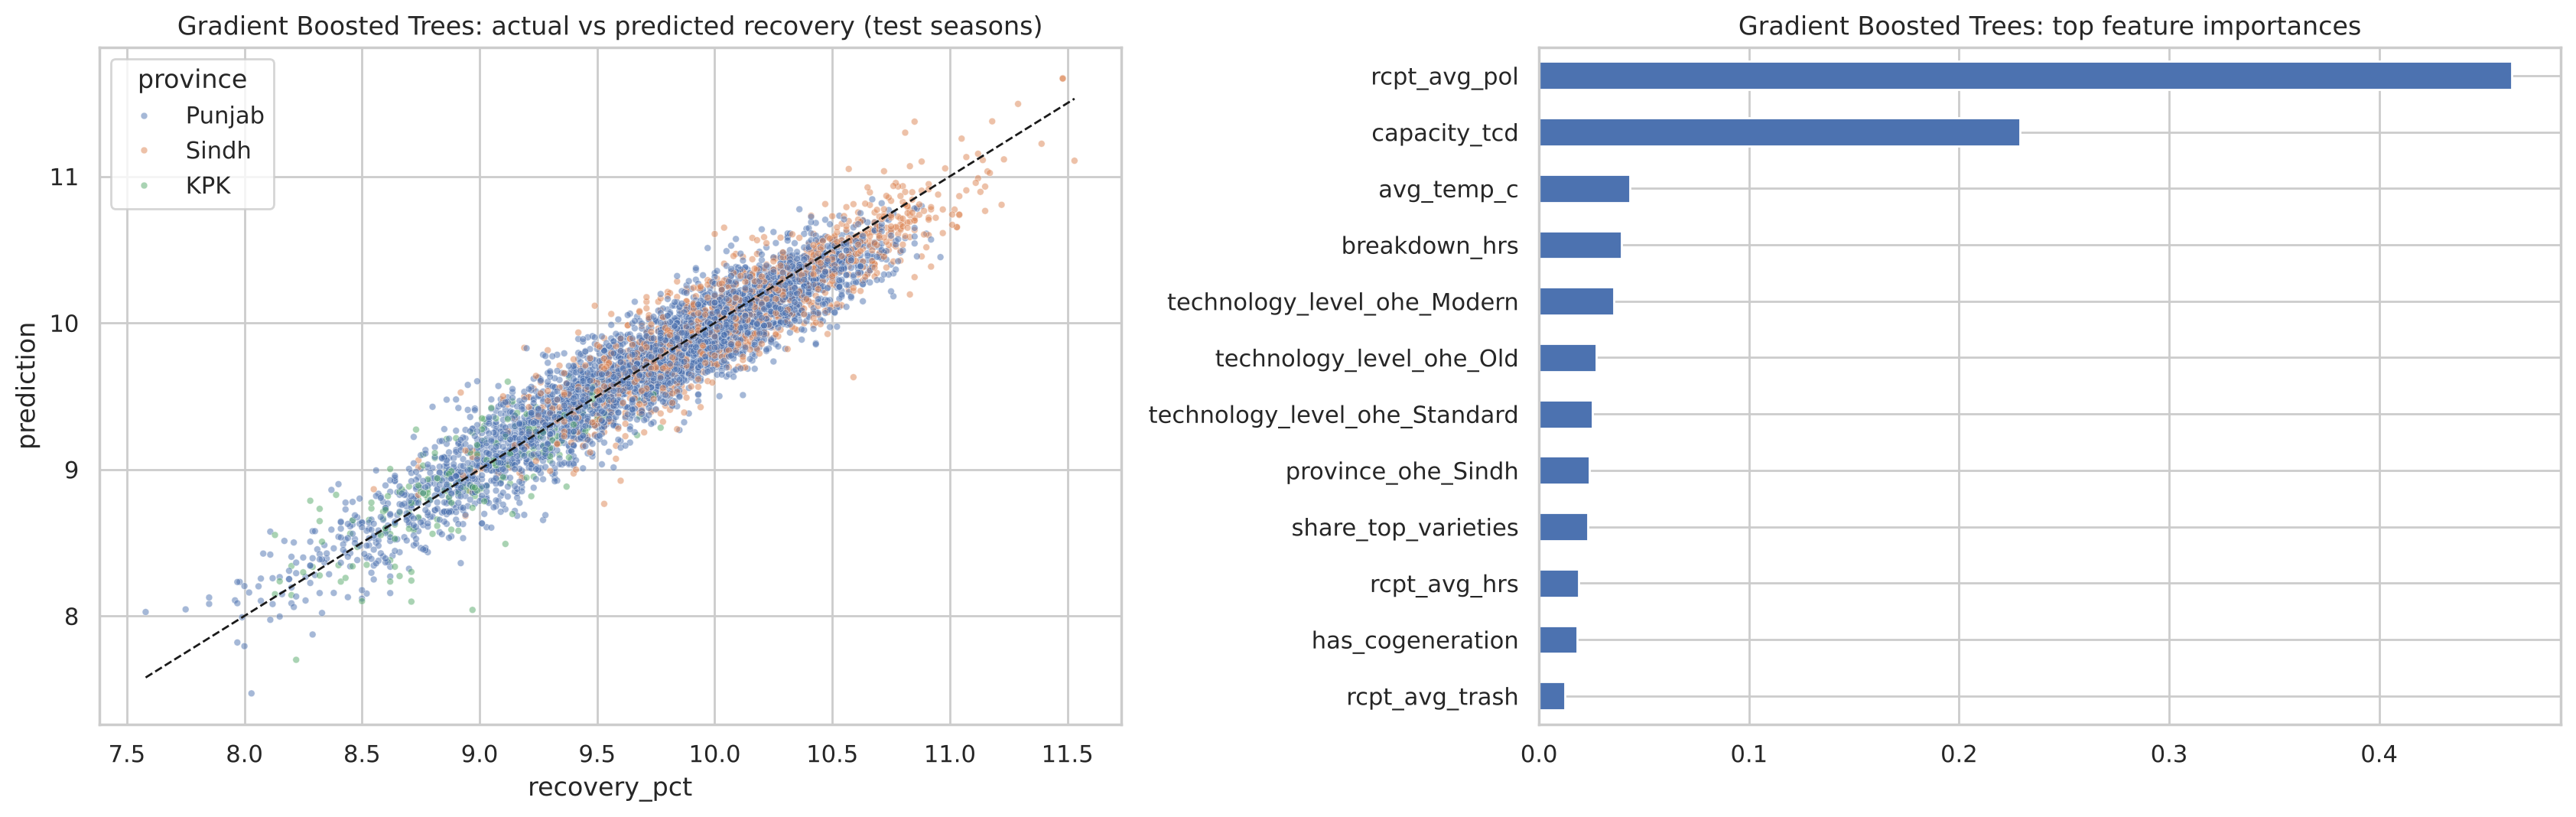

In [26]:
# Pick the model with the lowest RMSE and visualise its predictions and feature importances.
best_name = reg_results.sort_values("RMSE").iloc[0]["model"]
best_reg = fitted[best_name]
pred_pd = best_reg.transform(test).select("recovery_pct", "prediction", "province").sample(0.3, seed=3).toPandas()

# Recover readable feature names from the metadata Spark stores in the feature vector
attrs = best_reg.transform(test.limit(1)).schema["raw_features"].metadata["ml_attr"]["attrs"]
names = [n for _, n in sorted([(a["idx"], a["name"]) for k in attrs for a in attrs[k]])]
# featureImportances: how much each feature helped the trees reduce error (sums to 1)
imp = pd.Series(best_reg.stages[-1].featureImportances.toArray(), index=names).sort_values(ascending=True).tail(12)

fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
# Left: predicted vs actual. Points close to the dashed diagonal line = accurate predictions.
sns.scatterplot(data=pred_pd, x="recovery_pct", y="prediction", hue="province", s=10, alpha=0.5, ax=ax[0])
lims = [pred_pd.recovery_pct.min(), pred_pd.recovery_pct.max()]
ax[0].plot(lims, lims, "k--", lw=1); ax[0].set_title(f"{best_name}: actual vs predicted recovery (test seasons)")
imp.plot.barh(ax=ax[1], color="#4C72B0"); ax[1].set_title(f"{best_name}: top feature importances")
savefig("06_regression_results.png")

**Result.** Gradient Boosted Trees is the most accurate model on the two unseen seasons (test RMSE ≈ 0.19 percentage points, R² ≈ 0.89), ahead of Random Forest (R² ≈ 0.85, ≈ 0.86 after tuning) and the linear baseline (R² ≈ 0.80). The tree models capture non-linear effects such as the mid-season sucrose peak. By far the strongest predictor is the average pol % of cane received that day, followed by mill capacity and technology level, breakdown hours and temperature. In practice, a mill that measures the quality of incoming cane can forecast its recovery to within about ±0.2 percentage points.

## 8. Machine learning 2: predicting late payment to growers (classification)
**Business question:** which cane deliveries are at risk of being paid after the 15-day deadline? This could help a cane commissioner
target inspections, or help a grower choose which mill to supply.

**Label:** `is_late_payment = 1` if `payment_delay_days > 15`.
**Extra engineered feature:** each mill's late-payment rate in the **previous season** (a lag feature built with a window function), which
captures a mill's track record without leaking the current season's outcome.
A 25% random sample (~245k receipts) keeps training fast on Colab; 80/20 train/test split.

In [27]:
# ============================================================
# ML 2: PREPARE DATA for late-payment classification
# ============================================================
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

# Each mill's late-payment rate per season...
mill_season_late = proc.groupBy("mill_id", "season").agg(F.avg("is_late_payment").alias("late_rate"))
# ...shifted by one season with lag(): every row now holds the mill's rate from the PREVIOUS season.
# Using last season (not this season) avoids "leaking" the answer into the features.
mill_season_late = (mill_season_late
    .withColumn("prev_season_late_rate", F.lag("late_rate").over(Window.partitionBy("mill_id").orderBy("season")))
    .drop("late_rate"))
overall_late = proc.agg(F.avg("is_late_payment")).first()[0]     # overall late share, used to fill the first season (no history)

# Take a 25% random sample of receipts (keeps training quick on Colab) and add mill + grower attributes.
clf_df = (proc.sample(0.25, seed=42)
          .join(F.broadcast(mills_src.select("mill_id", "province", "technology_level", "ownership", "capacity_tcd",
                                             "has_distillery", "has_cogeneration")), "mill_id")
          .join(F.broadcast(growers_src.select("grower_id", "grower_type", "farm_size_acres")), "grower_id")
          .join(F.broadcast(mill_season_late), ["mill_id", "season"], "left")
          .fillna({"prev_season_late_rate": overall_late}))

C_NUM = ["month", "capacity_tcd", "has_distillery", "has_cogeneration", "farm_size_acres", "distance_km",
         "net_weight_t", "price_rs_per_40kg", "prev_season_late_rate"]                                     # numeric features
C_CAT = ["province", "technology_level", "ownership", "grower_type", "transport_mode", "payment_mode", "season"]   # categorical features
# Same preprocessing idea as ML 1: index text -> one-hot encode -> assemble vector -> scale
c_prep = ([StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in C_CAT] +
          [OneHotEncoder(inputCols=[c + "_idx" for c in C_CAT], outputCols=[c + "_ohe" for c in C_CAT]),
           VectorAssembler(inputCols=C_NUM + [c + "_ohe" for c in C_CAT], outputCol="raw_features"),
           StandardScaler(inputCol="raw_features", outputCol="features")])

# Random 80% / 20% split into training and test sets
c_train, c_test = clf_df.randomSplit([0.8, 0.2], seed=42)
c_train.cache(); c_test.cache()
print(f"train: {c_train.count():,} | test: {c_test.count():,} | late share: {overall_late:.1%}")

train: 196,156 | test: 48,527 | late share: 49.9%


In [28]:
# Train 3 classifiers that predict is_late_payment (1 = late, 0 = on time)
classifiers = {
    "Logistic Regression": LogisticRegression(labelCol="is_late_payment", maxIter=50, regParam=0.01),   # linear baseline
    "Random Forest": RandomForestClassifier(labelCol="is_late_payment", numTrees=60, maxDepth=10, seed=42),
    "Gradient Boosted Trees": GBTClassifier(labelCol="is_late_payment", maxIter=40, maxDepth=5, seed=42),
}
# AUC: how well the model ranks late above on-time (0.5 = guessing, 1.0 = perfect)
auc_ev = BinaryClassificationEvaluator(labelCol="is_late_payment", metricName="areaUnderROC")
# helper to build accuracy / precision / recall / F1 evaluators
mc = lambda m: MulticlassClassificationEvaluator(labelCol="is_late_payment", metricName=m)
clf_results, clf_models = [], {}
for name, est in classifiers.items():
    t0 = time.time()
    model = Pipeline(stages=c_prep + [est]).fit(c_train)        # preprocess + train
    pred = model.transform(c_test).cache()                      # predict on the test set
    clf_models[name] = model
    clf_results.append({"model": name, "AUC": round(auc_ev.evaluate(pred), 4),
                        "accuracy": round(mc("accuracy").evaluate(pred), 4),          # % of predictions that are correct
                        "precision": round(mc("weightedPrecision").evaluate(pred), 4), # of predicted late, how many were really late
                        "recall": round(mc("weightedRecall").evaluate(pred), 4),       # of real late payments, how many were caught
                        "F1": round(mc("f1").evaluate(pred), 4), "train_sec": round(time.time() - t0, 1)})  # F1 = balance of precision and recall
clf_results = pd.DataFrame(clf_results)
clf_results

,model,AUC,accuracy,precision,recall,F1,train_sec
0,Logistic Regression,0.8736,0.7887,0.7891,0.7887,0.7886,16.3
1,Random Forest,0.8845,0.8035,0.8048,0.8035,0.8033,42.9
2,Gradient Boosted Trees,0.8931,0.8104,0.8114,0.8104,0.8102,53.9


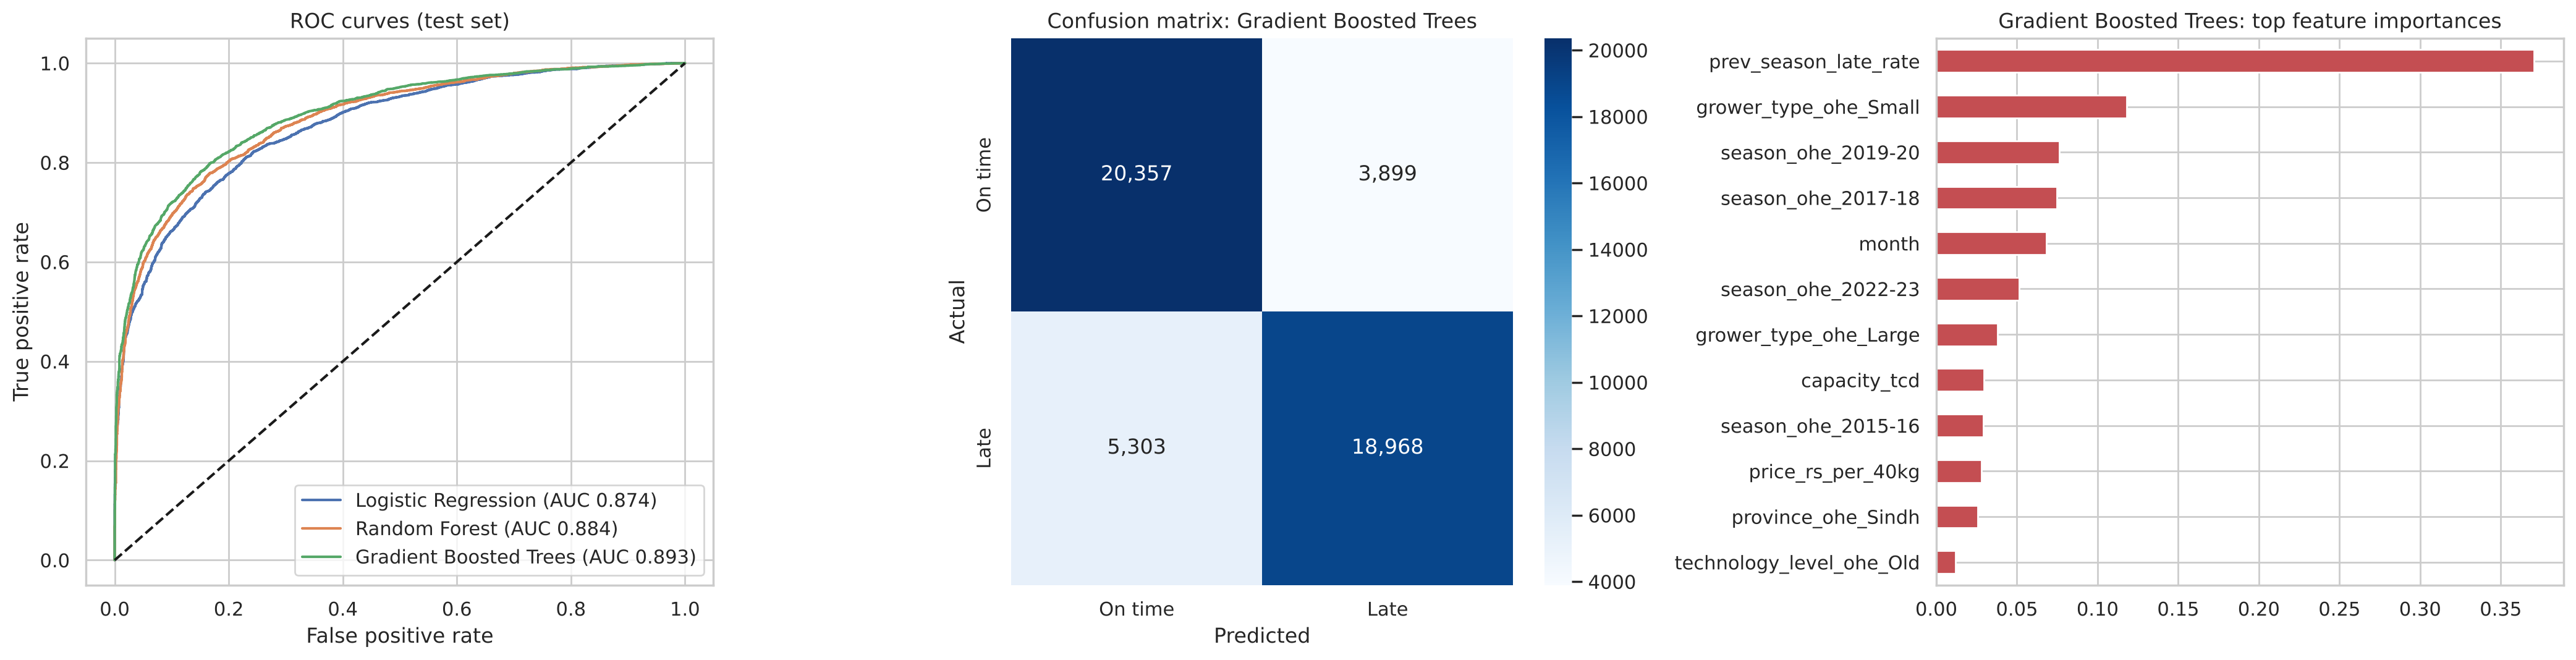

In [29]:
# Charts for ML 2: ROC curves, confusion matrix and feature importances
from sklearn.metrics import roc_curve, confusion_matrix
best_clf_name = clf_results.sort_values("AUC").iloc[-1]["model"]     # model with the highest AUC
fig, ax = plt.subplots(1, 3, figsize=(21, 5.5))
for name, model in clf_models.items():
    p = model.transform(c_test).select("is_late_payment", "probability").sample(0.2, seed=1).toPandas()
    p["p"] = p.probability.apply(lambda v: float(v[1]))              # probability of class 1 (late)
    fpr, tpr, _ = roc_curve(p.is_late_payment, p.p)                  # ROC curve points
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {clf_results.set_index('model').AUC[name]:.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC curves (test set)"); ax[0].legend()   # dashed line = random guessing
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")

# Confusion matrix: rows = actual class, columns = predicted class (diagonal = correct predictions)
bp = clf_models[best_clf_name].transform(c_test).select("is_late_payment", "prediction").toPandas()
cm = confusion_matrix(bp.is_late_payment, bp.prediction)
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", ax=ax[1], xticklabels=["On time", "Late"], yticklabels=["On time", "Late"])
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual"); ax[1].set_title(f"Confusion matrix: {best_clf_name}")

# Feature importances of the best model (same technique as in ML 1)
bm = clf_models[best_clf_name]
attrs = bm.transform(c_test.limit(1)).schema["raw_features"].metadata["ml_attr"]["attrs"]
names = [n for _, n in sorted([(a["idx"], a["name"]) for k in attrs for a in attrs[k]])]
imp = pd.Series(bm.stages[-1].featureImportances.toArray(), index=names).sort_values().tail(12)
imp.plot.barh(ax=ax[2], color="#C44E52"); ax[2].set_title(f"{best_clf_name}: top feature importances")
savefig("07_classification_results.png")

**Result.** All three classifiers separate on-time and late payments well (AUC 0.87 to 0.89); Gradient Boosted Trees is best (AUC ≈ 0.89, accuracy ≈ 81%). The engineered **previous-season late-payment rate** of the mill is the single most important feature: mills that paid late last season tend to pay late again. Small growers and surplus seasons (when sugar stocks are high and mills are short of cash) also raise the risk. A cane commissioner could use such a score to prioritise inspections of high-risk mills early in the season.

## 9. Data mining 1: K-Means clustering of sugar mills
**Goal:** group the 85 mills into performance segments without using any labels.
Each mill is described by 10 features aggregated over all its seasons (efficiency, reliability, grower relations, size).
Features are standardised, and **k** is chosen with the silhouette score and the elbow method.

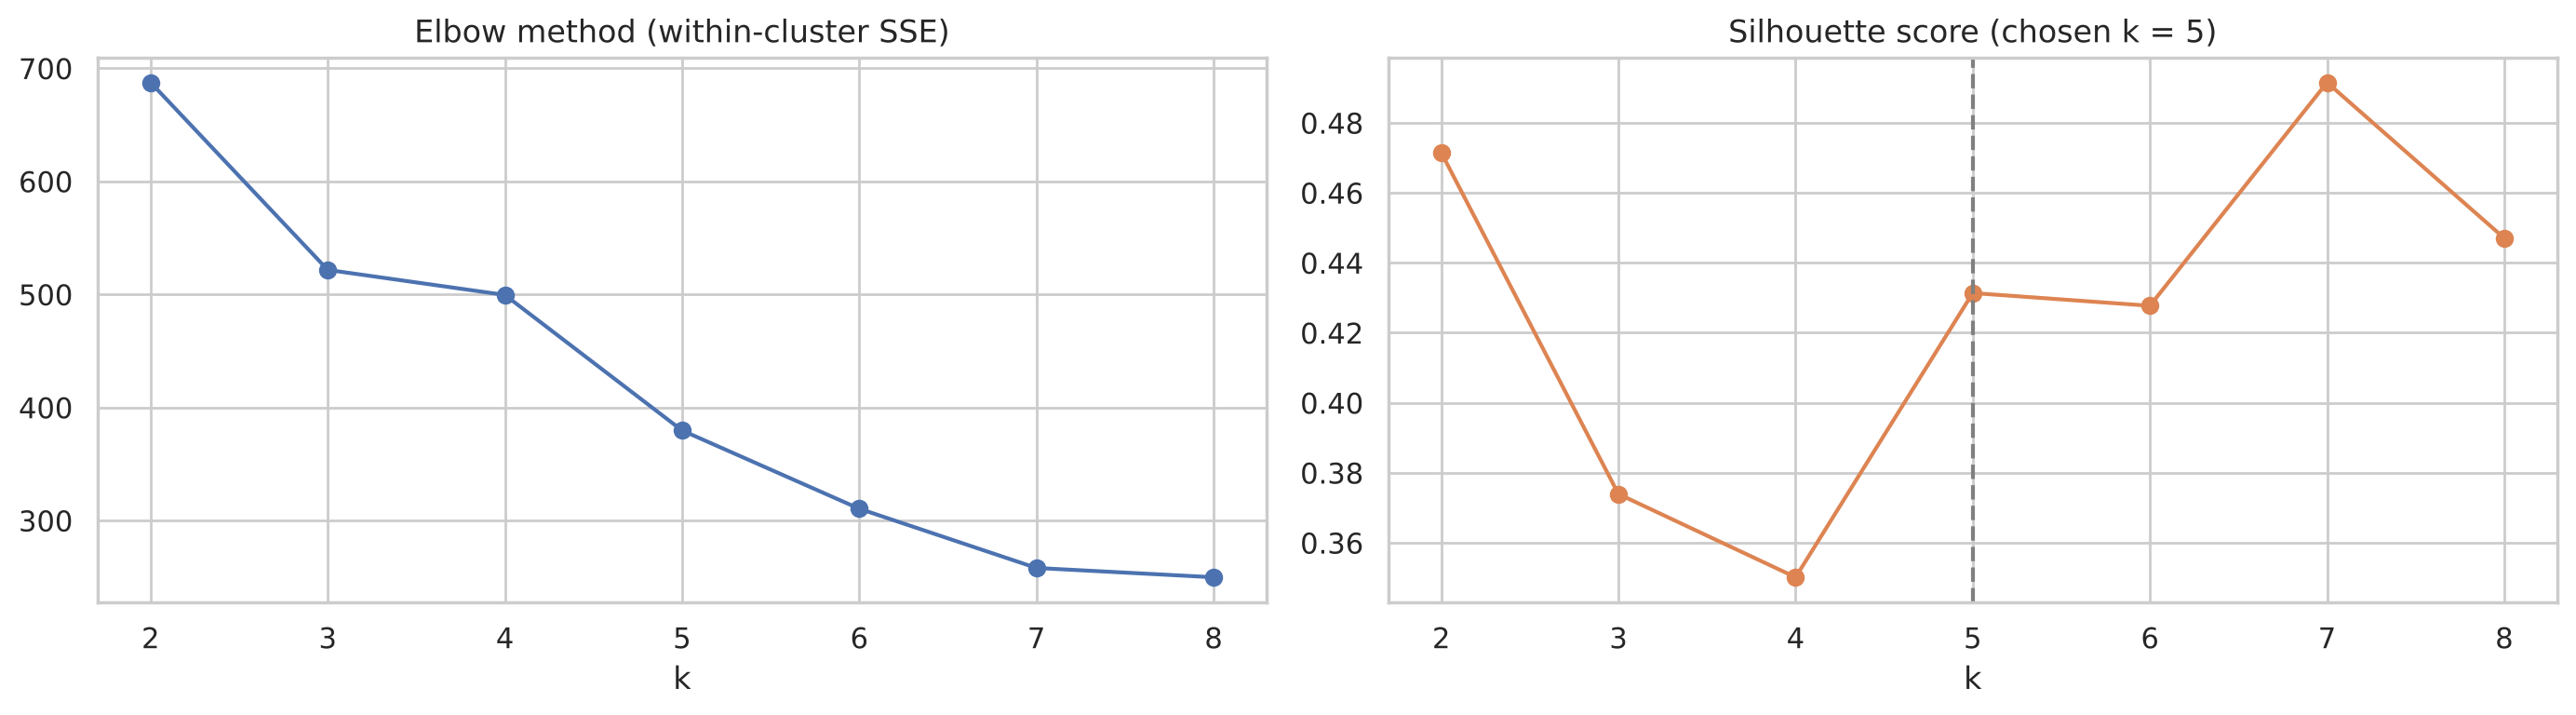

,k,silhouette,wcss
0,2,0.471,687.464
1,3,0.374,521.651
2,4,0.350,499.513
3,5,0.431,379.657
4,6,0.428,310.445
5,7,0.492,258.042
6,8,0.447,249.822


In [30]:
# ============================================================
# DATA MINING 1: K-MEANS CLUSTERING of mills
# ============================================================
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

# Operations profile: first per mill per season, then averaged over all seasons of each mill.
ops = (daily.groupBy("mill_id", "season").agg(F.count("*").alias("season_days"),
                                             (F.sum("sugar_produced_t") / F.sum("cane_crushed_t") * 100).alias("recovery"),
                                             F.avg("capacity_utilization_pct").alias("utilization"),
                                             F.sum("breakdown_hrs").alias("breakdown_hrs"),
                                             F.sum("power_exported_mwh").alias("power_mwh"))
       .groupBy("mill_id").agg(*[F.avg(c).alias(f"avg_{c}") for c in ["season_days", "recovery", "utilization",
                                                                        "breakdown_hrs", "power_mwh"]]))
# Grower-relations profile of each mill (payments and cane quality)
grower_rel = proc.groupBy("mill_id").agg(F.avg("payment_delay_days").alias("avg_payment_delay"),
                                         F.avg("is_late_payment").alias("late_share"),
                                         F.avg("cane_pol_pct").alias("avg_cane_pol"),
                                         F.avg("harvest_to_crush_hrs").alias("avg_harvest_to_crush"))
# One row per mill with all features + descriptive columns (used only to interpret clusters, not to build them)
mill_feat = ops.join(grower_rel, "mill_id").join(mills_src.select("mill_id", "capacity_tcd", "province", "technology_level",
                                                                  "ownership", "has_cogeneration"), "mill_id")
K_FEATS = ["avg_season_days", "avg_recovery", "avg_utilization", "avg_breakdown_hrs", "avg_power_mwh",
           "avg_payment_delay", "late_share", "avg_cane_pol", "avg_harvest_to_crush", "capacity_tcd"]
# K-Means uses distances, so features must be standardised (mean 0, std 1); otherwise big numbers like capacity would dominate.
km_data = Pipeline(stages=[VectorAssembler(inputCols=K_FEATS, outputCol="raw"),
                           StandardScaler(inputCol="raw", outputCol="features", withMean=True)]).fit(mill_feat).transform(mill_feat).cache()

# Try k = 2..8 clusters and record two quality measures for each
sil_ev = ClusteringEvaluator(featuresCol="features", metricName="silhouette")   # silhouette: -1..1, higher = better separated clusters
scores = []
for k in range(2, 9):
    m = KMeans(k=k, seed=42, featuresCol="features").fit(km_data)
    scores.append((k, sil_ev.evaluate(m.transform(km_data)), m.summary.trainingCost))   # trainingCost = within-cluster sum of squares (for the elbow chart)
scores = pd.DataFrame(scores, columns=["k", "silhouette", "wcss"])
# k between 3 and 5 keeps the segments interpretable; pick the best silhouette in that range
BEST_K = int(scores[scores.k.between(3, 5)].sort_values("silhouette", ascending=False).iloc[0].k)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(scores.k, scores.wcss, "o-"); ax[0].set_title("Elbow method (within-cluster SSE)"); ax[0].set_xlabel("k")
ax[1].plot(scores.k, scores.silhouette, "o-", c="#DD8452"); ax[1].axvline(BEST_K, ls="--", c="grey")
ax[1].set_title(f"Silhouette score (chosen k = {BEST_K})"); ax[1].set_xlabel("k")
savefig("08_kmeans_k_selection.png")
scores.round(3)

In [31]:
# Fit the final K-Means model and profile each cluster
from pyspark.ml.feature import PCA
kmeans_model = KMeans(k=BEST_K, seed=42, featuresCol="features").fit(km_data)
clustered = kmeans_model.transform(km_data).withColumnRenamed("prediction", "cluster")   # cluster number for each mill
# PCA squeezes the 10 features into 2 dimensions so the clusters can be drawn on a flat chart
clustered = PCA(k=2, inputCol="features", outputCol="pca").fit(clustered).transform(clustered)
cl = clustered.drop("raw", "features").toPandas()        # only 85 rows, safe to bring to pandas
cl["pc1"] = cl.pca.apply(lambda v: float(v[0])); cl["pc2"] = cl.pca.apply(lambda v: float(v[1]))

# Cluster profile = average of every feature inside each cluster
profile = cl.groupby("cluster")[K_FEATS].mean().round(2)
profile.insert(0, "mills", cl.groupby("cluster").size())
display(profile)
display(pd.crosstab(cl.cluster, cl.technology_level))    # how many Modern / Standard / Old mills in each cluster
display(pd.crosstab(cl.cluster, cl.province))            # how many mills of each province in each cluster

,mills,avg_season_days,avg_recovery,avg_utilization,avg_breakdown_hrs,avg_power_mwh,avg_payment_delay,late_share,avg_cane_pol,avg_harvest_to_crush,capacity_tcd
cluster,,,,,,,,,,,
0,30,82.12,10.02,77.27,47.84,4816.59,19.38,0.64,13.40,25.12,7790.00
1,6,45.00,8.98,59.67,14.76,9073.67,12.36,0.33,11.88,20.44,14550.00
2,30,138.36,9.54,83.75,87.87,2563.44,14.44,0.43,12.86,26.17,7803.33
3,17,131.19,9.98,91.10,41.20,36241.06,16.96,0.54,13.18,20.47,12017.65
4,2,45.00,8.73,49.74,34.80,0.00,23.67,0.84,11.63,27.81,7150.00


technology_level,Modern,Old,Standard
cluster,,,
0,7,9,14
1,5,0,1
2,0,9,21
3,14,0,3
4,0,1,1


province,KPK,Punjab,Sindh
cluster,,,
0,0,1,29
1,6,0,0
2,0,30,0
3,0,14,3
4,2,0,0


,segment,mills
0,High cane quality / Low season length,30
1,Low cane quality / Low utilisation,6
2,High breakdowns / High season length,30
3,High power export / High utilisation,17
4,Low utilisation / Low cane quality,2


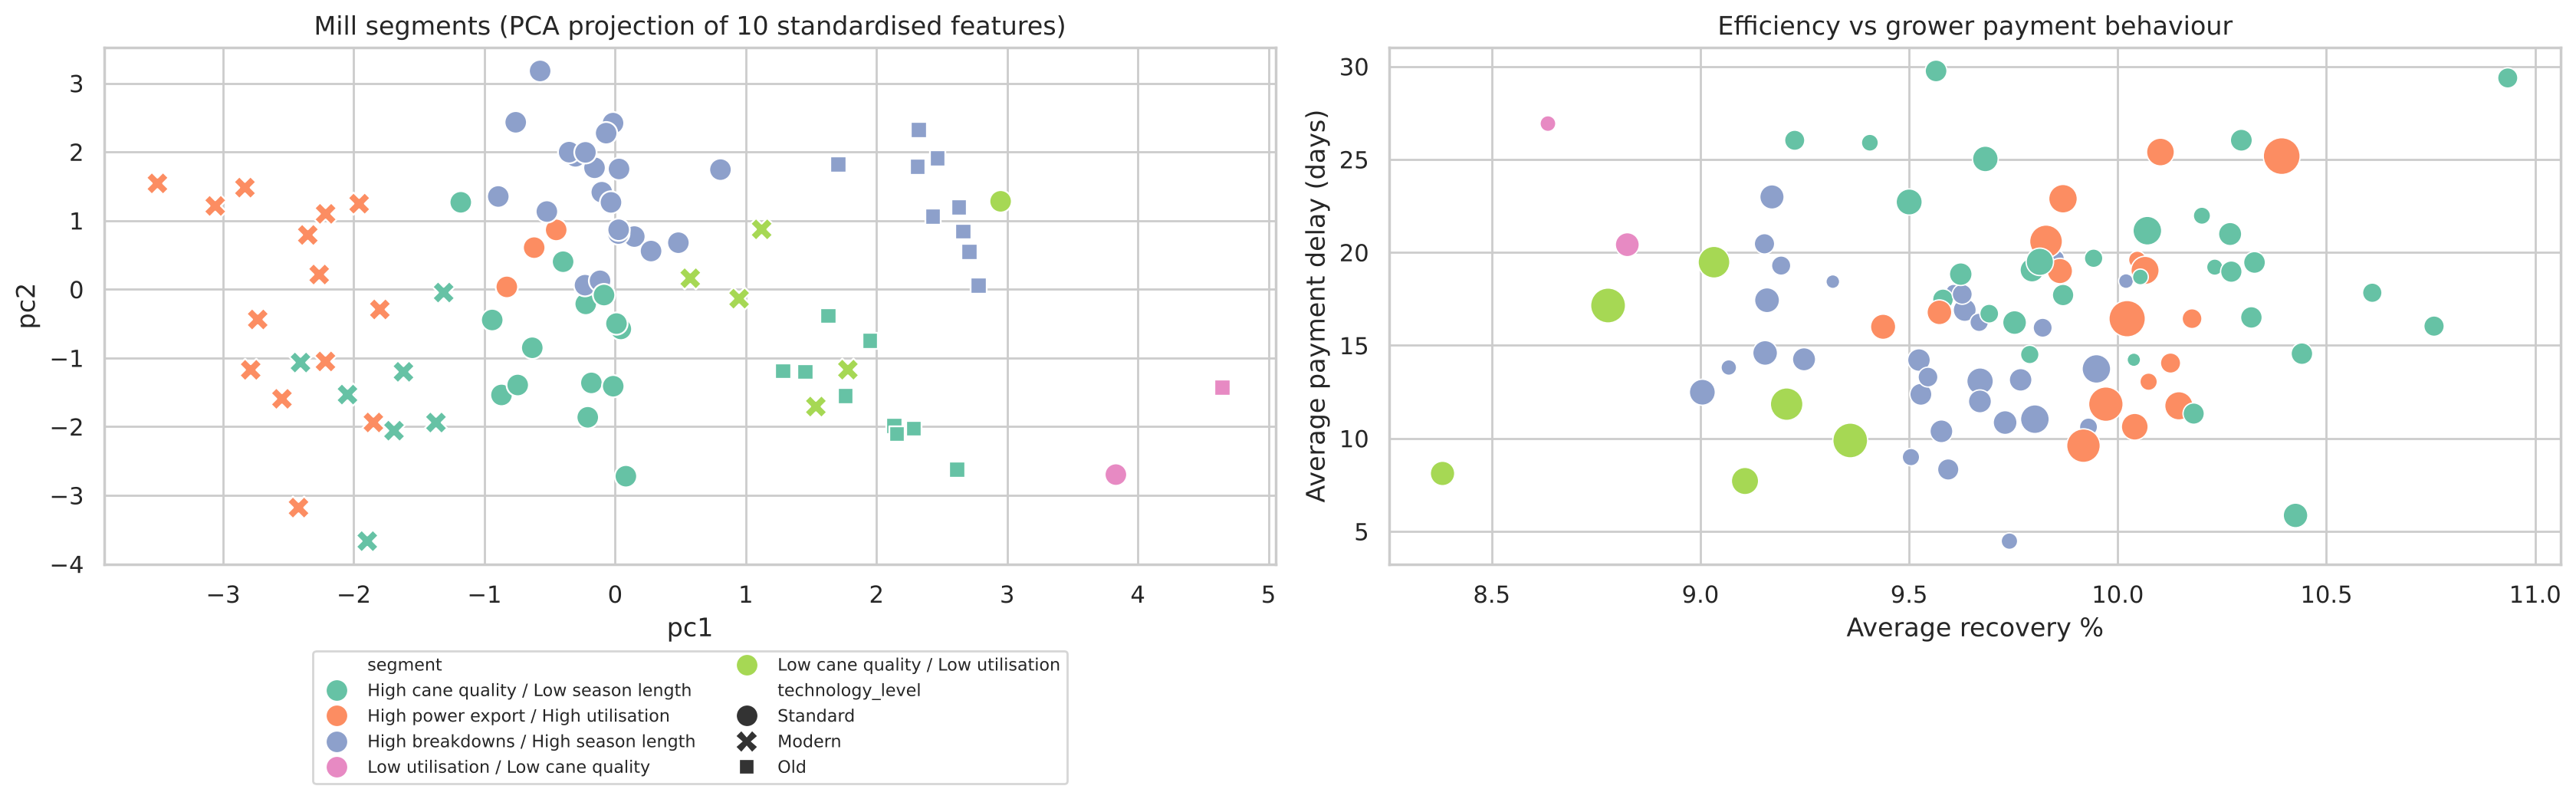

In [32]:
# Name each cluster automatically from the two features that set it apart most (z-scores vs all mills)
PRETTY = {"avg_season_days": "season length", "avg_recovery": "recovery", "avg_utilization": "utilisation",
          "avg_breakdown_hrs": "breakdowns", "avg_power_mwh": "power export", "avg_payment_delay": "payment delay",
          "late_share": "late payments", "avg_cane_pol": "cane quality", "avg_harvest_to_crush": "cane waiting time",
          "capacity_tcd": "capacity"}
# z-score = how many standard deviations a cluster's average is above (+) or below (-) the average of all mills
z = (profile[K_FEATS] - cl[K_FEATS].mean()) / cl[K_FEATS].std()
names_map = {}
for c, row in z.iterrows():
    top = row.abs().sort_values(ascending=False).index[:2]     # the 2 most extreme features of this cluster
    names_map[c] = " / ".join(f"{'High' if row[f] > 0 else 'Low'} {PRETTY[f]}" for f in top)
cl["segment"] = cl.cluster.map(names_map)
display(pd.DataFrame({"segment": names_map, "mills": profile.mills}))

fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
# Left: mills on the 2 PCA axes, coloured by segment, marker shape = technology level
sns.scatterplot(data=cl, x="pc1", y="pc2", hue="segment", style="technology_level", s=110, ax=ax[0], palette="Set2")
ax[0].set_title("Mill segments (PCA projection of 10 standardised features)")
ax[0].legend(bbox_to_anchor=(0.5, -0.15), loc="upper center", ncol=2, fontsize=8)
# Right: efficiency (recovery) vs grower treatment (payment delay); bubble size = capacity
sns.scatterplot(data=cl, x="avg_recovery", y="avg_payment_delay", hue="segment", size="capacity_tcd",
                sizes=(40, 300), ax=ax[1], palette="Set2", legend=False)
ax[1].set_xlabel("Average recovery %"); ax[1].set_ylabel("Average payment delay (days)")
ax[1].set_title("Efficiency vs grower payment behaviour")
savefig("09_kmeans_segments.png")
# Save each mill's cluster to a CSV file
cl[["mill_id", "province", "technology_level", "ownership", "cluster", "segment"] + K_FEATS].to_csv(
    os.path.join(OUT_DIR, "mill_clusters.csv"), index=False)

**Result.** The silhouette score (restricted to k = 3 to 5 for interpretability) selects **k = 5** segments (silhouette ≈ 0.43). In this run: (1) 30 Sindh mills with the best cane quality and high recovery but the most late payments; (2) 17 large modern Punjab mills with cogeneration, high utilisation and fresh cane; (3) 30 standard and old Punjab mills with long seasons and the most breakdowns; and two small KPK groups (6 and 2 mills) with short seasons, low cane quality and low utilisation. The segments show that **efficiency and grower treatment are separate dimensions**: the Sindh mills recover the most sugar yet pay growers the slowest.

## 10. Data mining 2: association rules with FP-Growth
**Goal:** discover which delivery conditions occur together, especially those linked to **high/low cane quality** and **late payment**.

Each receipt becomes a *transaction* (a basket of items) built from discretised attributes:
province, variety, month, transport mode, distance band, freshness (harvest-to-crush hours), trash band, grower type,
pol band (tertiles: Low / Medium / High) and payment status.
Spark's **FP-Growth** finds frequent itemsets without candidate generation, so it scales to hundreds of thousands of baskets.

In [33]:
# ============================================================
# DATA MINING 2: build "shopping baskets" for FP-Growth
# ============================================================
from pyspark.ml.fpm import FPGrowth

# Split pol % into 3 equal-sized groups (tertiles). approxQuantile finds the cut-off values quickly on big data.
q1, q2 = proc.approxQuantile("cane_pol_pct", [1/3, 2/3], 0.001)
print(f"Pol tertile cut-offs: {q1:.2f} and {q2:.2f}")
# A lookup map from month number to month name (11 -> "Nov", ...)
month_name = F.create_map(*[x for m, n in [(11, "Nov"), (12, "Dec"), (1, "Jan"), (2, "Feb"), (3, "Mar"), (4, "Apr"), (5, "May")]
                            for x in (F.lit(m), F.lit(n))])
# Each receipt becomes one transaction = a list ("basket") of text items such as "variety=CPF-249".
# Numbers are turned into bands (Near/Mid/Far, Fresh/Normal/Stale, Low/Medium/High) because
# association rules work on categories, not on continuous numbers.
basket = (proc.sample(0.25, seed=11)                       # 25% sample, ~245k transactions
    .join(F.broadcast(mills_src.select("mill_id", "province")), "mill_id")
    .join(F.broadcast(growers_src.select("grower_id", "grower_type")), "grower_id")
    .select(F.array(
        F.concat(F.lit("province="), "province"),
        F.concat(F.lit("variety="), "variety_code"),
        F.concat(F.lit("month="), month_name[F.col("month")]),
        F.concat(F.lit("transport="), "transport_mode"),
        F.concat(F.lit("distance="), F.when(F.col("distance_km") < 15, "Near(<15km)")
                 .when(F.col("distance_km") < 40, "Mid(15-40km)").otherwise("Far(40km+)")),
        F.concat(F.lit("freshness="), F.when(F.col("harvest_to_crush_hrs") < 18, "Fresh(<18h)")
                 .when(F.col("harvest_to_crush_hrs") < 36, "Normal(18-36h)").otherwise("Stale(36h+)")),
        F.concat(F.lit("trash="), F.when(F.col("trash_pct") < 3, "Low").when(F.col("trash_pct") < 5.5, "Medium").otherwise("High")),
        F.concat(F.lit("grower="), "grower_type"),
        F.concat(F.lit("pol="), F.when(F.col("cane_pol_pct") < q1, "Low").when(F.col("cane_pol_pct") < q2, "Medium").otherwise("High")),
        F.concat(F.lit("payment="), F.when(F.col("is_late_payment") == 1, "Late").otherwise("OnTime"))
    ).alias("items"))).cache()
print(f"Transactions: {basket.count():,}")
basket.show(3, truncate=False)

Pol tertile cut-offs: 12.72 and 13.50


Transactions: 244,771
+------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|items                                                                                                                                                                   |
+------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|[province=Punjab, variety=CP-77-400, month=Dec, transport=Truck, distance=Far(40km+), freshness=Fresh(<18h), trash=Medium, grower=Large, pol=Medium, payment=OnTime]    |
|[province=Punjab, variety=SPF-213, month=Dec, transport=Tractor-Trolley, distance=Far(40km+), freshness=Fresh(<18h), trash=Low, grower=Medium, pol=High, payment=OnTime]|
|[province=Punjab, variety=CP-77-400, month=Dec, transport=Truck, distance=Mid(15-40km), freshness=Normal(18-36h), trash=Hi

In [34]:
# Run FP-Growth
# minSupport 0.02   = an itemset must appear in at least 2% of all transactions to count as "frequent"
# minConfidence 0.5 = a rule A -> B is kept only if B happens in at least 50% of the transactions that contain A
t0 = time.time()
fp = FPGrowth(itemsCol="items", minSupport=0.02, minConfidence=0.5)
fp_model = fp.fit(basket)
itemsets = fp_model.freqItemsets          # all frequent item combinations with their counts
rules = fp_model.associationRules         # rules with confidence, lift and support
print(f"Frequent itemsets: {itemsets.count():,} | rules: {rules.count():,} | time {time.time()-t0:.1f} s")
itemsets.orderBy(F.desc("freq")).show(10, truncate=False)

Frequent itemsets: 5,294 | rules: 8,520 | time 34.9 s


+--------------------------------------------+------+
|items                                       |freq  |
+--------------------------------------------+------+
|[province=Punjab]                           |170676|
|[trash=Medium]                              |151026|
|[transport=Tractor-Trolley]                 |149474|
|[freshness=Normal(18-36h)]                  |124898|
|[payment=OnTime]                            |122731|
|[payment=Late]                              |122040|
|[distance=Mid(15-40km)]                     |115338|
|[trash=Medium, province=Punjab]             |105689|
|[transport=Tractor-Trolley, province=Punjab]|104203|
|[payment=OnTime, province=Punjab]           |94485 |
+--------------------------------------------+------+
only showing top 10 rows



In [35]:
# Turn the item lists into readable text and bring the rules to pandas
rules_pd = (rules.withColumn("antecedent", F.array_join("antecedent", " AND "))     # left side of the rule (IF ...)
            .withColumn("consequent", F.array_join("consequent", ", ")).toPandas())  # right side (THEN ...)
rules_pd = rules_pd.round(3)

# Return the strongest rules whose THEN-part starts with `target`.
# `exclude` removes trivial rules (e.g. using payment status to "predict" cane quality),
# and we keep only short rules with 1 or 2 conditions so they are easy to read.
# lift > 1 means the items occur together more often than by chance (lift 2 = twice as often).
def top_rules(target, exclude, n=10):
    r = rules_pd[rules_pd.consequent.str.startswith(target) & ~rules_pd.antecedent.str.contains(exclude)]
    r = r[r.antecedent.str.count(" AND ") <= 1]          # keep short, readable rules (1-2 items)
    return r.sort_values(["lift", "confidence"], ascending=False).head(n)[["antecedent", "consequent", "support", "confidence", "lift"]]

pd.set_option("display.max_colwidth", 80)
print("Rules predicting HIGH cane quality:"); display(top_rules("pol=High", "payment="))
print("Rules predicting LOW cane quality:"); display(top_rules("pol=Low", "payment="))
print("Rules predicting LATE payment:"); display(top_rules("payment=Late", "pol="))

Rules predicting HIGH cane quality:


,antecedent,consequent,support,confidence,lift
298,variety=CPF-249 AND month=Jan,pol=High,0.027,0.717,2.129
5608,variety=CPF-249 AND province=Sindh,pol=High,0.034,0.704,2.090
5044,month=Jan AND province=Sindh,pol=High,0.059,0.645,1.916
5596,month=Jan AND freshness=Fresh(<18h),pol=High,0.049,0.626,1.859
7759,trash=Low AND province=Sindh,pol=High,0.034,0.624,1.853
1125,province=Sindh AND freshness=Fresh(<18h),pol=High,0.057,0.611,1.815
3736,variety=CPF-249 AND trash=Low,pol=High,0.020,0.607,1.803
5571,month=Feb AND freshness=Fresh(<18h),pol=High,0.032,0.591,1.756
4357,trash=Low AND month=Jan,pol=High,0.034,0.590,1.753
3053,variety=CPF-249 AND freshness=Fresh(<18h),pol=High,0.031,0.589,1.748


Rules predicting LOW cane quality:


,antecedent,consequent,support,confidence,lift
3651,province=KPK AND transport=Tractor-Trolley,pol=Low,0.021,0.854,2.590
4471,province=KPK,pol=Low,0.034,0.853,2.588
5240,province=KPK AND trash=Medium,pol=Low,0.020,0.844,2.560
2779,month=Apr AND freshness=Normal(18-36h),pol=Low,0.033,0.831,2.521
906,month=Apr AND trash=Medium,pol=Low,0.044,0.812,2.462
8249,month=Apr AND grower=Large,pol=Low,0.021,0.803,2.437
504,month=Apr AND transport=Truck,pol=Low,0.024,0.801,2.431
2518,month=Apr AND distance=Mid(15-40km),pol=Low,0.033,0.801,2.431
7599,month=Apr AND grower=Small,pol=Low,0.024,0.800,2.428
2432,month=Apr AND province=Punjab,pol=Low,0.070,0.799,2.423


Rules predicting LATE payment:


,antecedent,consequent,support,confidence,lift
6856,month=Nov AND province=Sindh,payment=Late,0.025,0.783,1.570
3315,province=Sindh AND month=Dec,payment=Late,0.081,0.765,1.534
330,province=Sindh AND grower=Small,payment=Late,0.069,0.762,1.528
1267,variety=Thatta-10 AND grower=Small,payment=Late,0.021,0.760,1.525
5631,variety=Thatta-10 AND month=Dec,payment=Late,0.024,0.760,1.524
2314,month=Dec AND grower=Small,payment=Late,0.070,0.725,1.454
2032,variety=CPF-249 AND month=Dec,payment=Late,0.030,0.714,1.432
5610,variety=CPF-249 AND province=Sindh,payment=Late,0.035,0.710,1.424
7601,month=Apr AND grower=Small,payment=Late,0.021,0.702,1.408
6938,month=Mar AND grower=Small,payment=Late,0.034,0.691,1.385


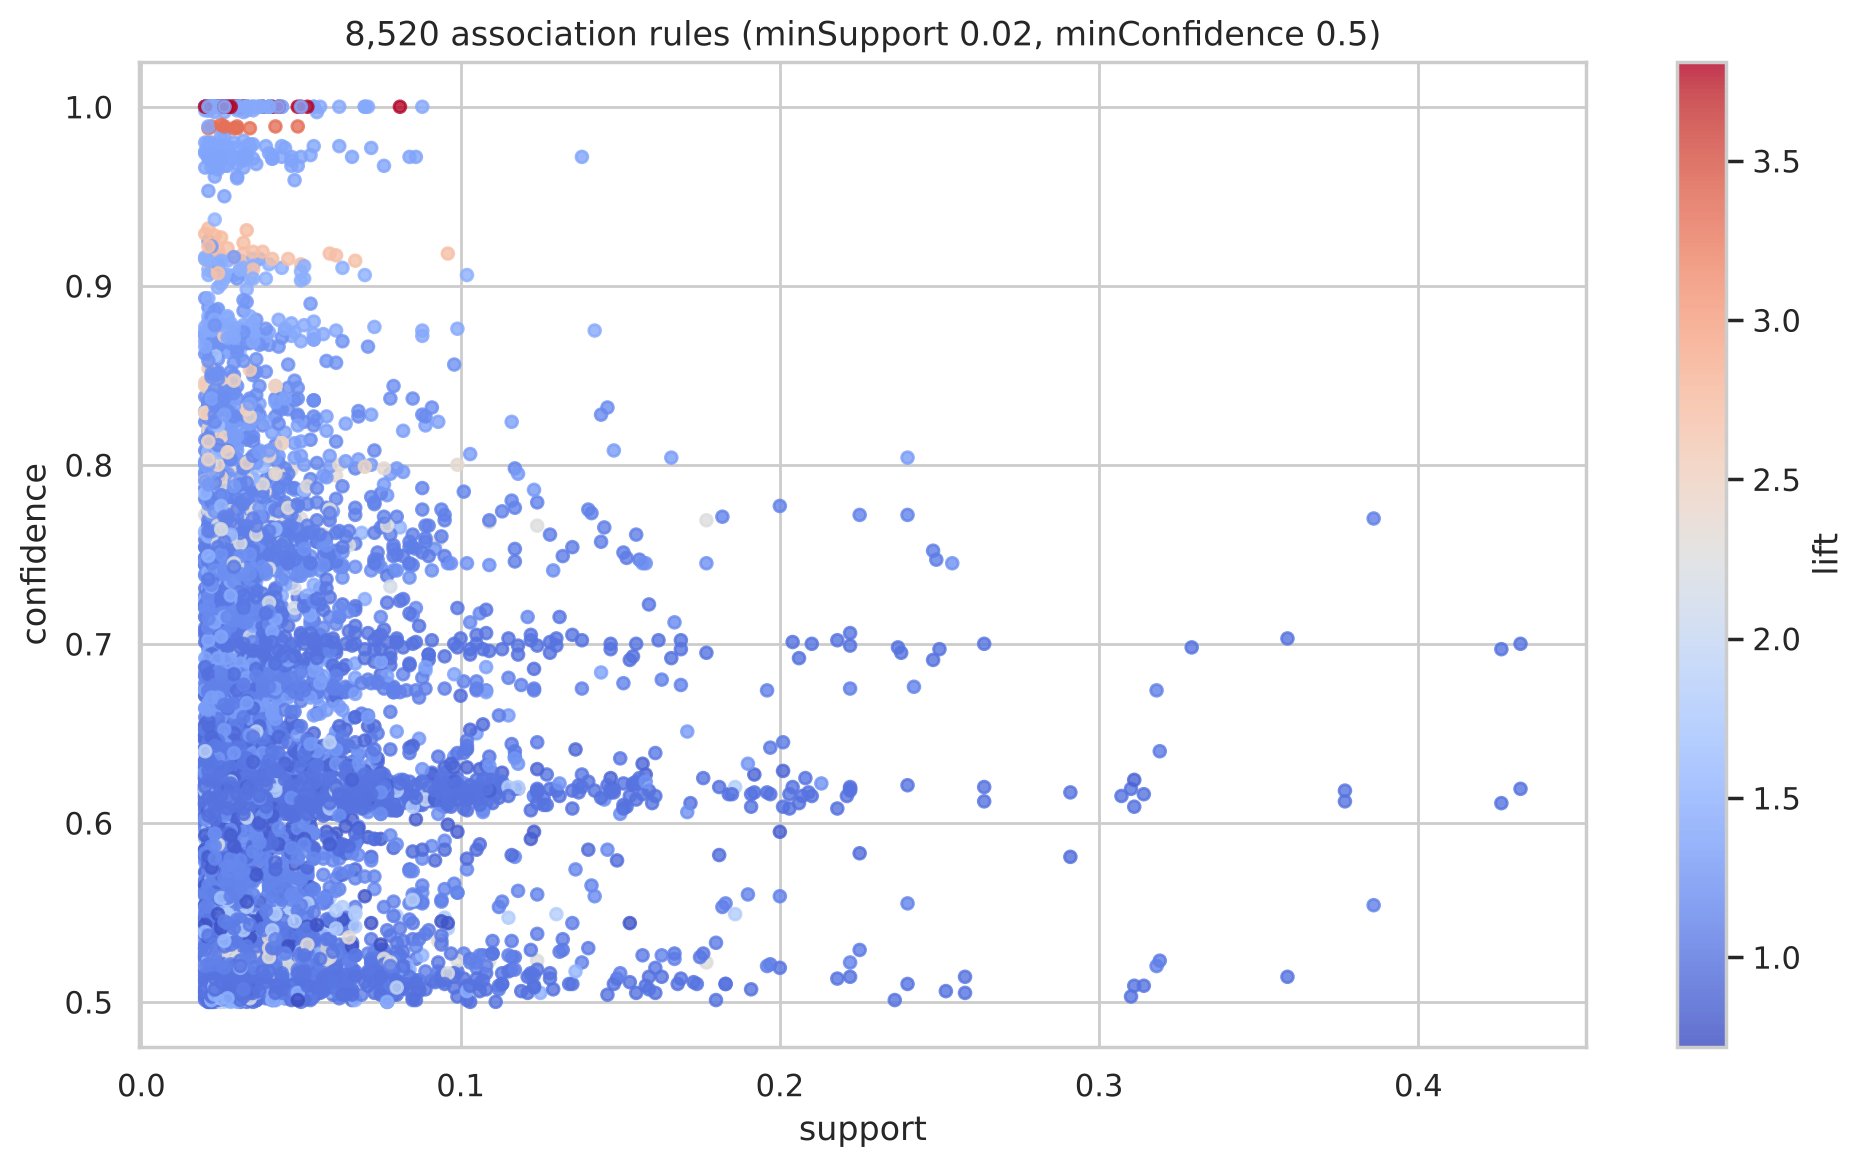

In [36]:
# Scatter plot of all rules: x = support (how common), y = confidence (how reliable), colour = lift (how interesting)
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(rules_pd.support, rules_pd.confidence, c=rules_pd.lift, cmap="coolwarm", s=18, alpha=0.8)
plt.colorbar(sc, label="lift"); ax.set_xlabel("support"); ax.set_ylabel("confidence")
ax.set_title(f"{len(rules_pd):,} association rules (minSupport 0.02, minConfidence 0.5)")
savefig("10_association_rules.png")
# Save all rules (strongest first) to a CSV file
rules_pd.sort_values("lift", ascending=False).to_csv(os.path.join(OUT_DIR, "association_rules.csv"), index=False)

**Result.** FP-Growth found about 5,300 frequent itemsets and 8,500 rules from ~245k transactions in about half a minute. Key patterns (lift > 1 means the combination occurs more often than by chance):
* **High cane quality**: variety CPF-249 delivered in January (lift ≈ 2.1), Sindh cane in January, and fresh cane (under 18 hours from harvest) with low trash.
* **Low cane quality**: KPK cane (lift ≈ 2.6) and deliveries in April (late-season staling, lift ≈ 2.5).
* **Late payment**: Sindh deliveries in November and December and small growers in Sindh (confidence ≈ 76 to 78%, lift ≈ 1.5).

These rules are directly actionable: crush fresh cane quickly, schedule the best varieties for the peak months, and target payment enforcement at Sindh mills buying from small growers.

## 11. Save results

In [37]:
# Save the result tables and the two best trained models (they can be reloaded later with PipelineModel.load)
reg_results.to_csv(os.path.join(OUT_DIR, "regression_metrics.csv"), index=False)
clf_results.to_csv(os.path.join(OUT_DIR, "classification_metrics.csv"), index=False)
best_reg.write().overwrite().save(os.path.join(PROJECT_DIR, "models", "recovery_regressor"))
clf_models[best_clf_name].write().overwrite().save(os.path.join(PROJECT_DIR, "models", "late_payment_classifier"))
print("Saved metrics, clusters, rules and models.")
print(sorted(os.listdir(OUT_DIR)))

Saved metrics, clusters, rules and models.
['association_rules.csv', 'classification_metrics.csv', 'figures', 'mill_clusters.csv', 'regression_metrics.csv']


## 12. Conclusions
| Area | Key outcome |
|---|---|
| Big data | ~980k receipts + 85k mill-days processed with PySpark; 1,470 duplicate receipts and 712 impossible lab readings removed, about 5,200 missing values imputed |
| Data warehouse | Galaxy schema with 2 facts and 4 dimensions; zstd Parquet partitioned by season is ~30% smaller than CSV.gz and answers a seasonal query more than twice as fast thanks to partition and column pruning |
| OLAP | Roll-up, cube, slice, dice, drill-down, pivot and window ranking show Sindh has the highest recovery (≈10.1%) while recovery peaks in January-February everywhere |
| Regression | Gradient Boosted Trees predicts daily recovery with R² ≈ 0.89 on unseen seasons; incoming cane pol is the key driver |
| Classification | Gradient Boosted Trees flags late grower payments with AUC ≈ 0.89; a mill's past behaviour is the best predictor |
| Clustering | 5 mill segments; technical efficiency and timely grower payment do not always go together |
| Association rules | Fresh, January-harvested, high-sucrose varieties give high pol; April and KPK cane give low pol; Sindh deliveries and small growers face most late payments |

**Recommendations for the industry:** cut harvest-to-crush time, expand high-sucrose varieties such as CPF-249, concentrate crushing in the December to February window, invest in modernisation and cogeneration for the oldest mills, and monitor mills with a history of late payments.

To run a heavier Big Data workload, regenerate the data with `python src/generate_data.py --scale 1` (~2.5M receipts) or `--scale 4` (~10M receipts); the notebook runs unchanged.

## Limitations and future work
* Mill-level and receipt-level data are **simulated** (calibrated to real national and provincial figures). With access to real
  PSMA or cane commissioner data, the same pipeline runs unchanged on real records.
* Weather is simulated per district; joining real PMD or ERA5 weather data would strengthen the recovery model.
* Next steps: streaming ingestion of weighbridge receipts with Spark Structured Streaming, a Power BI / Superset dashboard on top of
  the Parquet warehouse, and season-ahead production forecasting.

In [38]:
# Shut down Spark and free the memory it was using
spark.stop()